# Przygotowanie danych

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from tensorflow.keras.models import Sequential  # type: ignore
from tensorflow.keras.layers import Dense, Dropout, Input  # type: ignore
from tensorflow.keras.optimizers import Adam  # type: ignore
from tensorflow.keras.callbacks import EarlyStopping  # type: ignore
from tensorflow.keras.backend import clear_session  # type: ignore

I0000 00:00:1792333491.103637   54592 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792333491.427327   54592 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792333493.045934   54592 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
def read_currency_data(filepath: str, start_date: str):
    """
    reads file and cuts the unnecessary data: League and Confidence.
    Date is changed into day of the league, to transform date into number.
    returns DataFrame
    """
    df = pd.read_csv(filepath, sep=';', skipinitialspace=True)
    df['Date'] = pd.to_datetime(df['Date'])
    df = df[df['Pay'] == 'Chaos Orb']
    df['Day of league'] = (df['Date'] - pd.to_datetime(start_date)).dt.days + 1
    columns_to_drop = ['League', 'Date', 'Pay', 'Confidence']
    df = df.drop(columns=columns_to_drop)
    df = df.reset_index(drop=True)
    return df


def transform_currency_data(df):
    """
    Drop with all NaN
    Drop with 5 NaN's in Row - bad data
    Fill NaN's with data from day before, and fill first day's
    Cuts data to 100 days (Settlers is too large)
    returns DataFrame
    """
    df = df.pivot(index='Day of league', columns='Get', values='Value')
    df = df.dropna(axis=1, how='all')
    df = df.dropna(axis=1, thresh=len(df) - 4)
    df = df.ffill().bfill()
    df = df[df.index <= 100]
    return df.T


keepers_df = transform_currency_data(
    read_currency_data('data/Keepers.currency.csv', '2025-10-31'))
mercenaries_df = transform_currency_data(
    read_currency_data('data/Mercenaries.currency.csv', '2025-06-13'))
settlers_df = transform_currency_data(
    read_currency_data('data/Settlers.currency.csv', '2024-07-26'))
affiliction_df = transform_currency_data(
    read_currency_data('data/Affliction.currency.csv', '2023-12-08'))
necropolis_df = transform_currency_data(
    read_currency_data('data/Necropolis.currency.csv', '2024-03-29'))

In [3]:
ITEM = "Divine Orb"
WINDOW = 14
TEST_LIGA = -1
leagues = [necropolis_df, affiliction_df,
           settlers_df, mercenaries_df, keepers_df]
league_names = ['Necropolis', 'Affliction', 'Settlers', 'Mercenaries', 'Keepers']
test_idx = TEST_LIGA % len(leagues)
tscv = TimeSeriesSplit()

## Podział danych

In [4]:
def normalize(series):
    base = series.iloc[0]
    if base == 0 or pd.isna(base):
        return None
    return series / base


def make_windows(series, window):
    X, y = [], []
    for i in range(window, len(series)):
        X.append(series.iloc[i-window:i].values)
        y.append(series.iloc[i])
    return np.array(X), np.array(y)


X_train_list, y_train_list = [], []
for i, df in enumerate(leagues):
    if i == test_idx:
        continue
    if ITEM not in df.index:
        continue

    raw_series = df.loc[ITEM].dropna()

    norm = normalize(raw_series)
    if norm is None:
        continue

    X, y = make_windows(norm, WINDOW)

    X_train_list.append(X)
    y_train_list.append(y)

X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)
print(f"Dane treningowe: {X_train.shape}")

scaler_standard = StandardScaler()
X_train_standard = scaler_standard.fit_transform(X_train)

df_test = leagues[test_idx]
raw_test = df_test.loc[ITEM].dropna()
norm_test = normalize(raw_test)
base_price = raw_test.iloc[0]
initial_window = norm_test.iloc[:WINDOW].values

Dane treningowe: (344, 14)


# Modele

In [5]:
def forecast_regression(model, scaler, initial_window, full_series_norm, base_price):
    """
    Prognoza rekurencyjna krok po kroku: okno jest uzupełniane
    rzeczywistymi wartościami z serii testowej.
    """
    window = len(initial_window)
    buf = list(initial_window)
    preds_norm = []
    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        x = scaler.transform(x_raw)
        pred = model.predict(x)[0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])
    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds


def evaluate(actuals, preds):
    return {
        'MAE': mean_absolute_error(actuals, preds),
        'MAPE': mean_absolute_percentage_error(actuals, preds) * 100,
        'MSE': mean_squared_error(actuals, preds),
        'R2': r2_score(actuals, preds),
    }


def print_metrics(m, params=None):
    print(f"  MAE:  {m['MAE']:.2f}")
    print(f"  MAPE: {m['MAPE']:.2f}%")
    print(f"  MSE:  {m['MSE']:.2f}")
    print(f"  R²:   {m['R2']:.4f}")
    if params is not None:
        print(f"  best params: {params}")


# wspólne słowniki z wynikami: klucz = nazwa modelu
results = {}
preds_all = {}
actuals_test = None

## Random Forest

In [6]:
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train_standard, y_train)

actuals_test, preds = forecast_regression(
    rf_grid.best_estimator_, scaler_standard, initial_window, norm_test, base_price)

metrics = evaluate(actuals_test, preds)
results['Random Forest'] = {**metrics, 'best_params': rf_grid.best_params_}
preds_all['Random Forest'] = preds
print_metrics(metrics, rf_grid.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  4.01
  MAPE: 2.52%
  MSE:  31.31
  R²:   0.9131
  best params: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


## Support Vector Regression

In [7]:
svr_param_grid = {
    'kernel': ['rbf', 'linear'],
    'C': [1, 10, 100],
    'epsilon': [0.05, 0.1],
    'gamma': ['scale', 0.1, 1]
}

svr_grid = GridSearchCV(
    estimator=SVR(),
    param_grid=svr_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
svr_grid.fit(X_train_standard, y_train)

_, preds = forecast_regression(
    svr_grid.best_estimator_, scaler_standard, initial_window, norm_test, base_price)

metrics = evaluate(actuals_test, preds)
results['SVR'] = {**metrics, 'best_params': svr_grid.best_params_}
preds_all['SVR'] = preds
print_metrics(metrics, svr_grid.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.72
  MAPE: 1.79%
  MSE:  16.60
  R²:   0.9540
  best params: {'C': 10, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}


## K Neighbors Regressor

In [8]:
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'p': [1, 2],
    'algorithm': ['auto', 'ball_tree', 'kd_tree']
}

knn_grid = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)
knn_grid.fit(X_train_standard, y_train)

_, preds = forecast_regression(
    knn_grid.best_estimator_, scaler_standard, initial_window, norm_test, base_price)

metrics = evaluate(actuals_test, preds)
results['KNN'] = {**metrics, 'best_params': knn_grid.best_params_}
preds_all['KNN'] = preds
print_metrics(metrics, knn_grid.best_params_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
  MAE:  7.44
  MAPE: 4.85%
  MSE:  89.41
  R²:   0.7519
  best params: {'algorithm': 'auto', 'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}


## Neural Network

In [9]:
def build_nn_model(layers, activations='relu', dropout_rate=0.3, learning_rate=0.001):
    """
    Buduje sieć neuronową na podstawie listy warstw.

    Parametry:
        layers: lista liczb całkowitych – liczba neuronów w kolejnych warstwach ukrytych.
                Np. [5,10,15,10,5] stworzy 5 warstw ukrytych.
        activations: funkcja aktywacji dla wszystkich warstw (str) lub lista takich samych
                     długości jak layers, określająca aktywację dla każdej warstwy.
        dropout_rate: współczynnik dropoutu (dodawany po każdej warstwie ukrytej).
        learning_rate: szybkość uczenia.
    """
    model = Sequential()
    model.add(Input(shape=(WINDOW,)))

    if isinstance(activations, str):
        act_list = [activations] * len(layers)
    else:
        act_list = activations
        if len(act_list) != len(layers):
            raise ValueError(
                "Długość listy aktywacji musi być równa liczbie warstw.")

    for i, units in enumerate(layers):
        model.add(Dense(units, activation=act_list[i]))
        if i < len(layers) - 1:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model


def forecast_nn(model, scaler, initial_window_norm, full_series_norm, base_price):
    window = len(initial_window_norm)
    buf = list(initial_window_norm)
    preds_norm = []

    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        x_scaled = scaler.transform(x_raw)
        pred = model.predict(x_scaled, verbose=0)[0, 0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])

    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds

In [10]:
nn_configs = [
    {'layers': [64, 32, 16], 'dropout': 0.3,
        'lr': 0.001, 'activations': 'relu'},
    {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001,
        'activations': ['elu', 'elu', 'elu', 'relu']},
    {'layers': [8, 16, 32, 64, 32, 16, 8], 'dropout': 0.2,
        'lr': 0.0005, 'activations': 'relu'},
    {'layers': [32, 32, 32, 32, 32], 'dropout': 0.4,
        'lr': 0.001, 'activations': 'leaky_relu'},
]

best_nn_mae = float('inf')
best_nn_config = None
best_nn_model = None

for config in nn_configs:
    clear_session()
    print(f"Testowanie: {config}")
    nn_model = build_nn_model(
        layers=config['layers'],
        activations=config.get('activations', 'relu'),
        dropout_rate=config['dropout'],
        learning_rate=config['lr']
    )
    early_stop = EarlyStopping(
        monitor='val_loss', patience=15, restore_best_weights=True)

    nn_model.fit(
        X_train_standard, y_train,
        epochs=150, batch_size=32, validation_split=0.1,
        callbacks=[early_stop], verbose=0
    )

    val_preds = nn_model.predict(X_train_standard[-100:], verbose=0)
    val_mae = mean_absolute_error(y_train[-100:], val_preds.flatten())
    print(f"  Val MAE: {val_mae:.4f}")

    if val_mae < best_nn_mae:
        best_nn_mae = val_mae
        best_nn_config = config
        best_nn_model = nn_model

_, preds = forecast_nn(
    best_nn_model, scaler_standard, initial_window, norm_test, base_price)

metrics = evaluate(actuals_test, preds)
results['Sieć neuronowa'] = {**metrics, 'best_params': best_nn_config}
preds_all['Sieć neuronowa'] = preds
print_metrics(metrics, best_nn_config)

Testowanie: {'layers': [64, 32, 16], 'dropout': 0.3, 'lr': 0.001, 'activations': 'relu'}


E0000 00:00:1792333506.704221   54592 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


  Val MAE: 1.0710
Testowanie: {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}
  Val MAE: 0.0865
Testowanie: {'layers': [8, 16, 32, 64, 32, 16, 8], 'dropout': 0.2, 'lr': 0.0005, 'activations': 'relu'}
  Val MAE: 0.3478
Testowanie: {'layers': [32, 32, 32, 32, 32], 'dropout': 0.4, 'lr': 0.001, 'activations': 'leaky_relu'}
  Val MAE: 0.2322
  MAE:  7.17
  MAPE: 4.75%
  MSE:  70.57
  R²:   0.8042
  best params: {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}


## Naiwny

In [11]:
# Model naiwny: prognoza na dzień t = rzeczywista cena z dnia t-1 (na lidze testowej)
naive_preds_norm = norm_test.iloc[WINDOW - 1:-1].values
preds = naive_preds_norm * base_price

metrics = evaluate(actuals_test, preds)
results['Naiwny'] = {**metrics, 'best_params': ''}
preds_all['Naiwny'] = preds
print_metrics(metrics)

  MAE:  2.56
  MAPE: 1.69%
  MSE:  17.11
  R²:   0.9525


# Podsumowanie

In [12]:
rows = []
for model_name, m in results.items():
    rows.append({
        'Model': model_name,
        'MAE': m['MAE'],
        'MAPE': m['MAPE'],
        'MSE': m['MSE'],
        'R²': m['R2'],
        'Najlepsze parametry': str(m['best_params'])
    })

df_results = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.4f}'.format)

print(f"Liga testowa: {league_names[test_idx]}, przedmiot: {ITEM}\n")
print(df_results.to_string(index=False))

print("\n" + "=" * 80)
print("NAJLEPSZE WYNIKI")
print("=" * 80)

for metric in ['MAE', 'MAPE', 'MSE']:
    best_row = df_results.loc[df_results[metric].idxmin()]
    print(f"Najlepszy wynik dla {metric}: {best_row['Model']} ({best_row[metric]:.4f})")

best_row = df_results.loc[df_results['R²'].idxmax()]
print(f"Najlepszy wynik dla R²: {best_row['Model']} ({best_row['R²']:.4f})")

Liga testowa: Keepers, przedmiot: Divine Orb

         Model    MAE   MAPE     MSE     R²                                                                                      Najlepsze parametry
        Naiwny 2.5578 1.6913 17.1072 0.9525                                                                                                         
           SVR 2.7183 1.7883 16.5969 0.9540                                         {'C': 10, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}
 Random Forest 4.0066 2.5183 31.3055 0.9131                    {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Sieć neuronowa 7.1680 4.7455 70.5665 0.8042 {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}
           KNN 7.4375 4.8459 89.4110 0.7519                                    {'algorithm': 'auto', 'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}

NAJLEPSZE WYNIKI
Najlepszy wynik dla MAE: Naiwny (2.5578)
N

## Wizualizacja

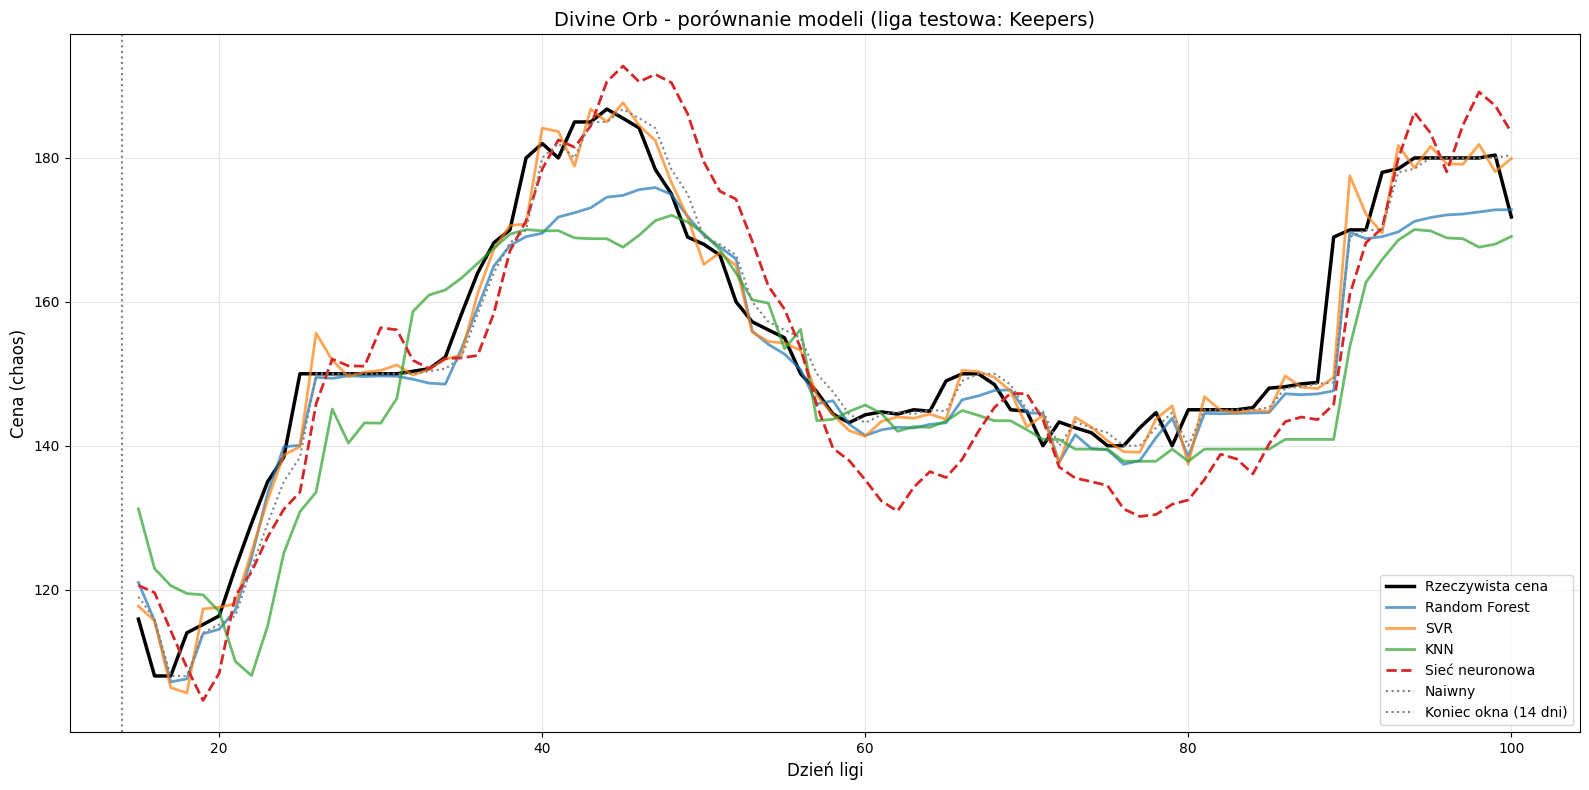

In [13]:
n_test = len(actuals_test)
days_preds = range(WINDOW + 1, WINDOW + n_test + 1)

model_styles = {
    'Random Forest':  {'alpha': 0.7, 'linewidth': 2},
    'SVR':            {'alpha': 0.7, 'linewidth': 2},
    'KNN':            {'alpha': 0.7, 'linewidth': 2},
    'Sieć neuronowa': {'linestyle': '--', 'linewidth': 2},
    'Naiwny':         {'color': 'gray', 'linestyle': ':', 'linewidth': 1.5},
}

plt.figure(figsize=(16, 8))
plt.plot(days_preds, actuals_test, label='Rzeczywista cena',
         color='black', lw=2.5)

for model_name, preds in preds_all.items():
    plt.plot(days_preds, preds, label=model_name, **model_styles[model_name])

plt.axvline(x=WINDOW, color='gray', linestyle=':',
            label=f'Koniec okna ({WINDOW} dni)')
plt.title(f'{ITEM} - porównanie modeli (liga testowa: {league_names[test_idx]})',
          fontsize=14)
plt.xlabel('Dzień ligi', fontsize=12)
plt.ylabel('Cena (chaos)', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

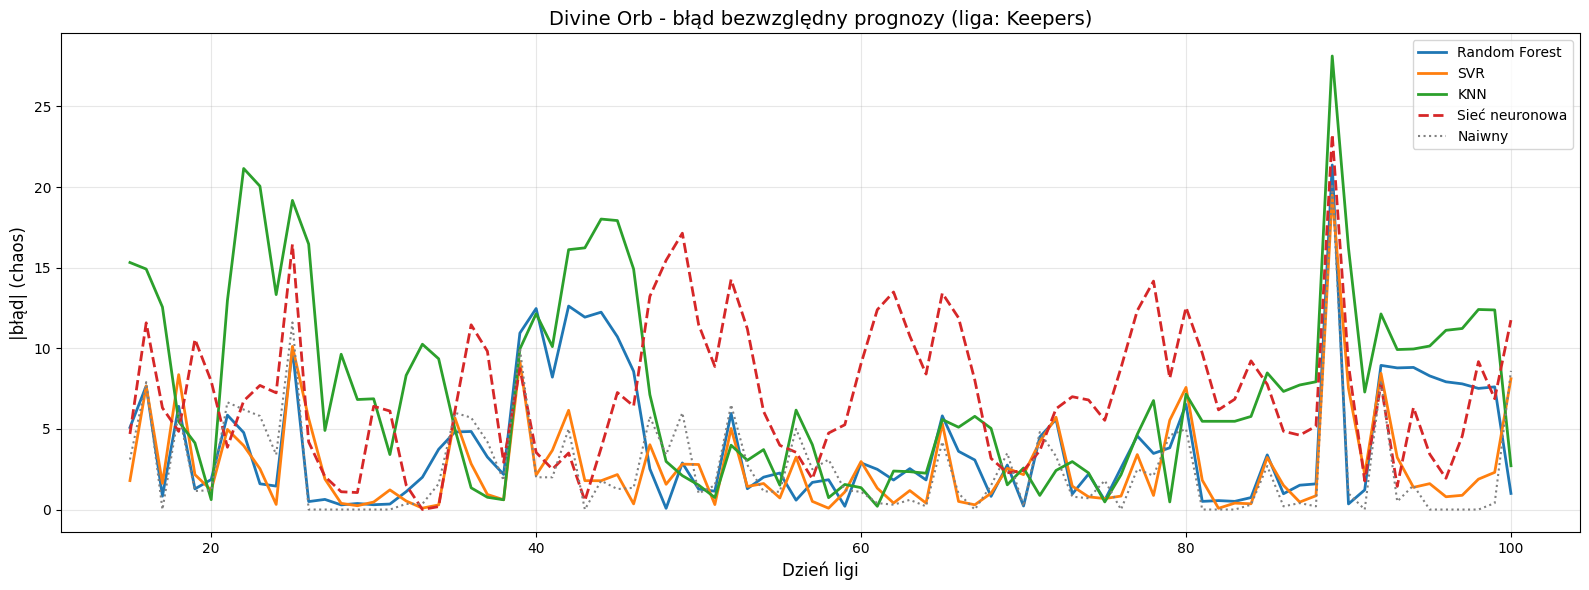

In [14]:
# Błąd bezwzględny w czasie dla każdego modelu
plt.figure(figsize=(16, 6))
for model_name, preds in preds_all.items():
    plt.plot(days_preds, np.abs(actuals_test - preds), label=model_name,
             **{k: v for k, v in model_styles[model_name].items() if k != 'alpha'})
plt.title(f'{ITEM} - błąd bezwzględny prognozy (liga: {league_names[test_idx]})',
          fontsize=14)
plt.xlabel('Dzień ligi', fontsize=12)
plt.ylabel('|błąd| (chaos)', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Każdy model vs. cena rzeczywista

Dla każdego modelu osobny wykres: cena rzeczywista (czarna linia) i prognoza modelu, z zaznaczonym błędem.
Po nim drugi zestaw wykresów z różnicą cen (prognoza − cena rzeczywista): wartości powyżej zera oznaczają zawyżenie ceny, poniżej zera zaniżenie.
Wszystkie modele z `preds_all` są rysowane automatycznie, bez wybierania.

Zapisano: plots/Divine_Orb_Keepers_cena_vs_modele.png
Zapisano: plots/Divine_Orb_Keepers_cena_vs_modele.pdf


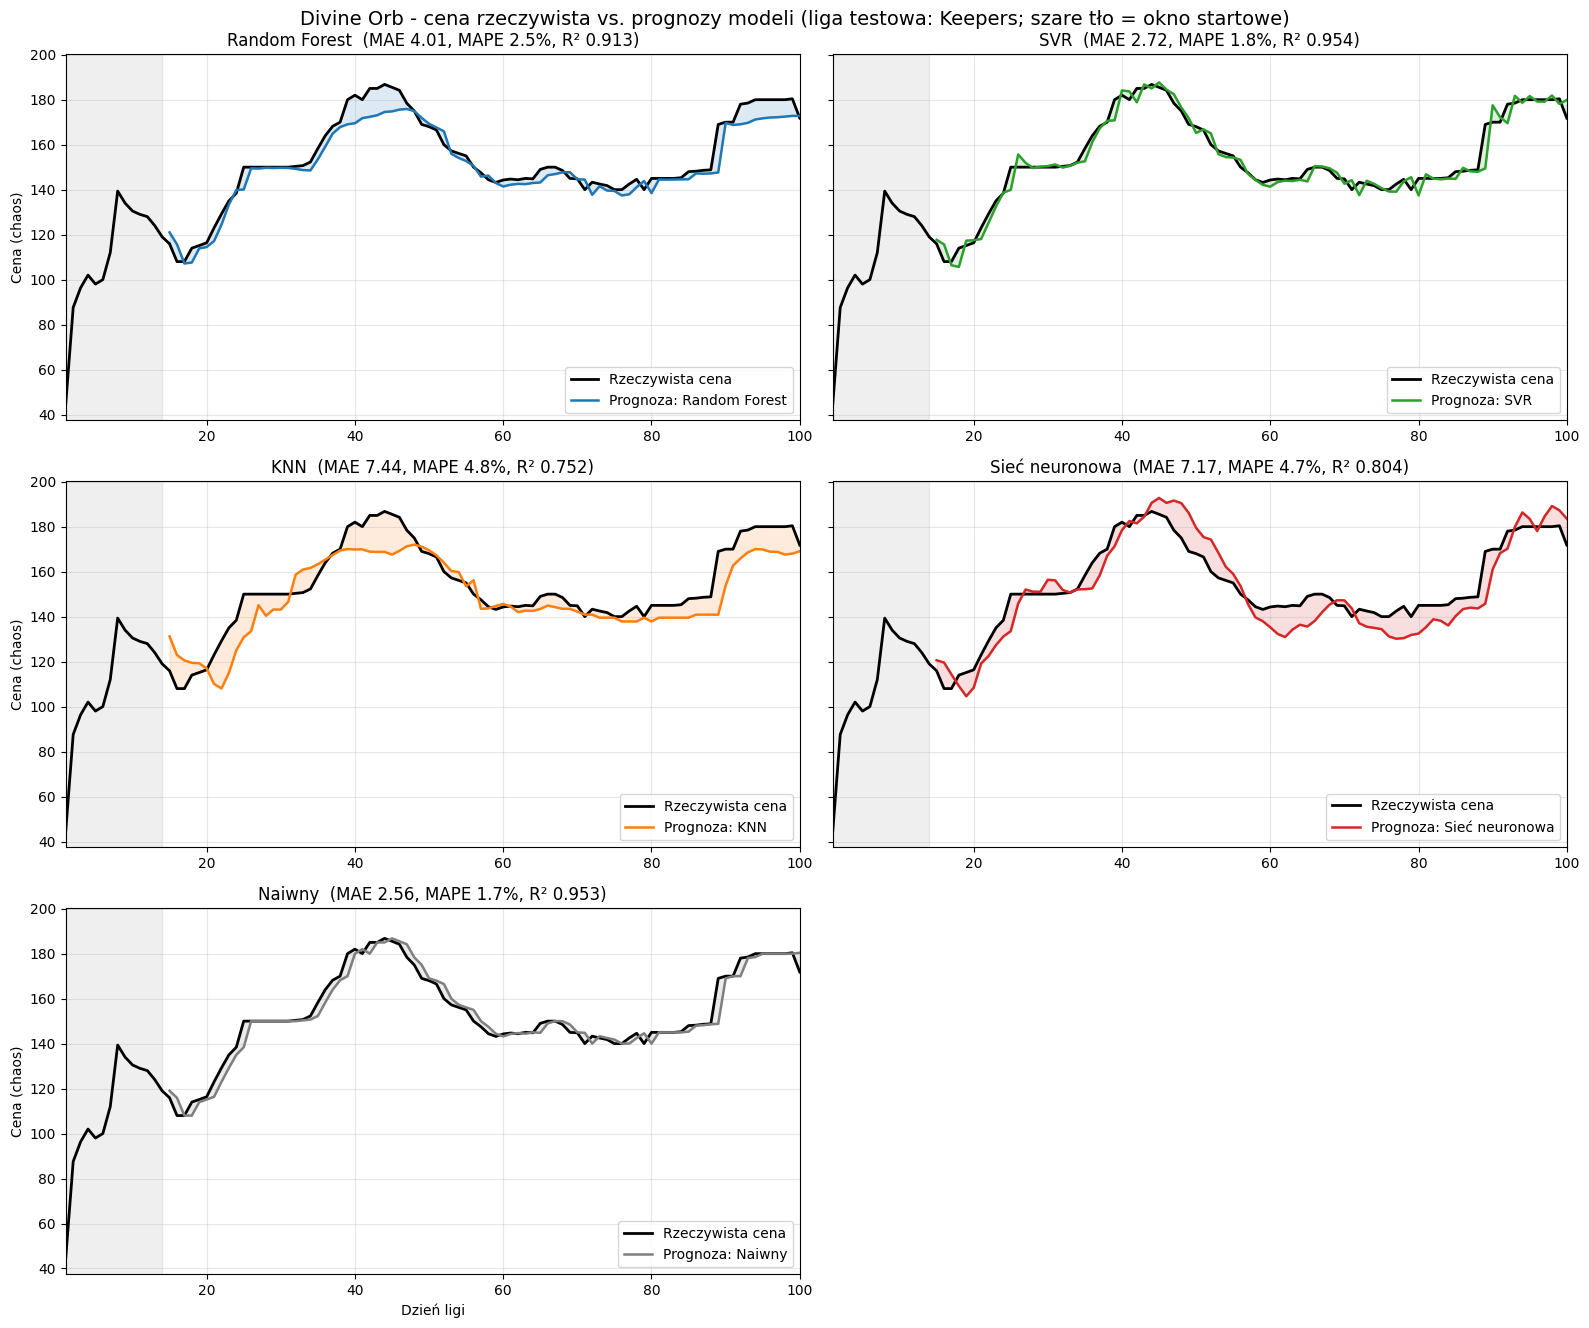

Zapisano: plots/Divine_Orb_Keepers_roznica_cen.png
Zapisano: plots/Divine_Orb_Keepers_roznica_cen.pdf


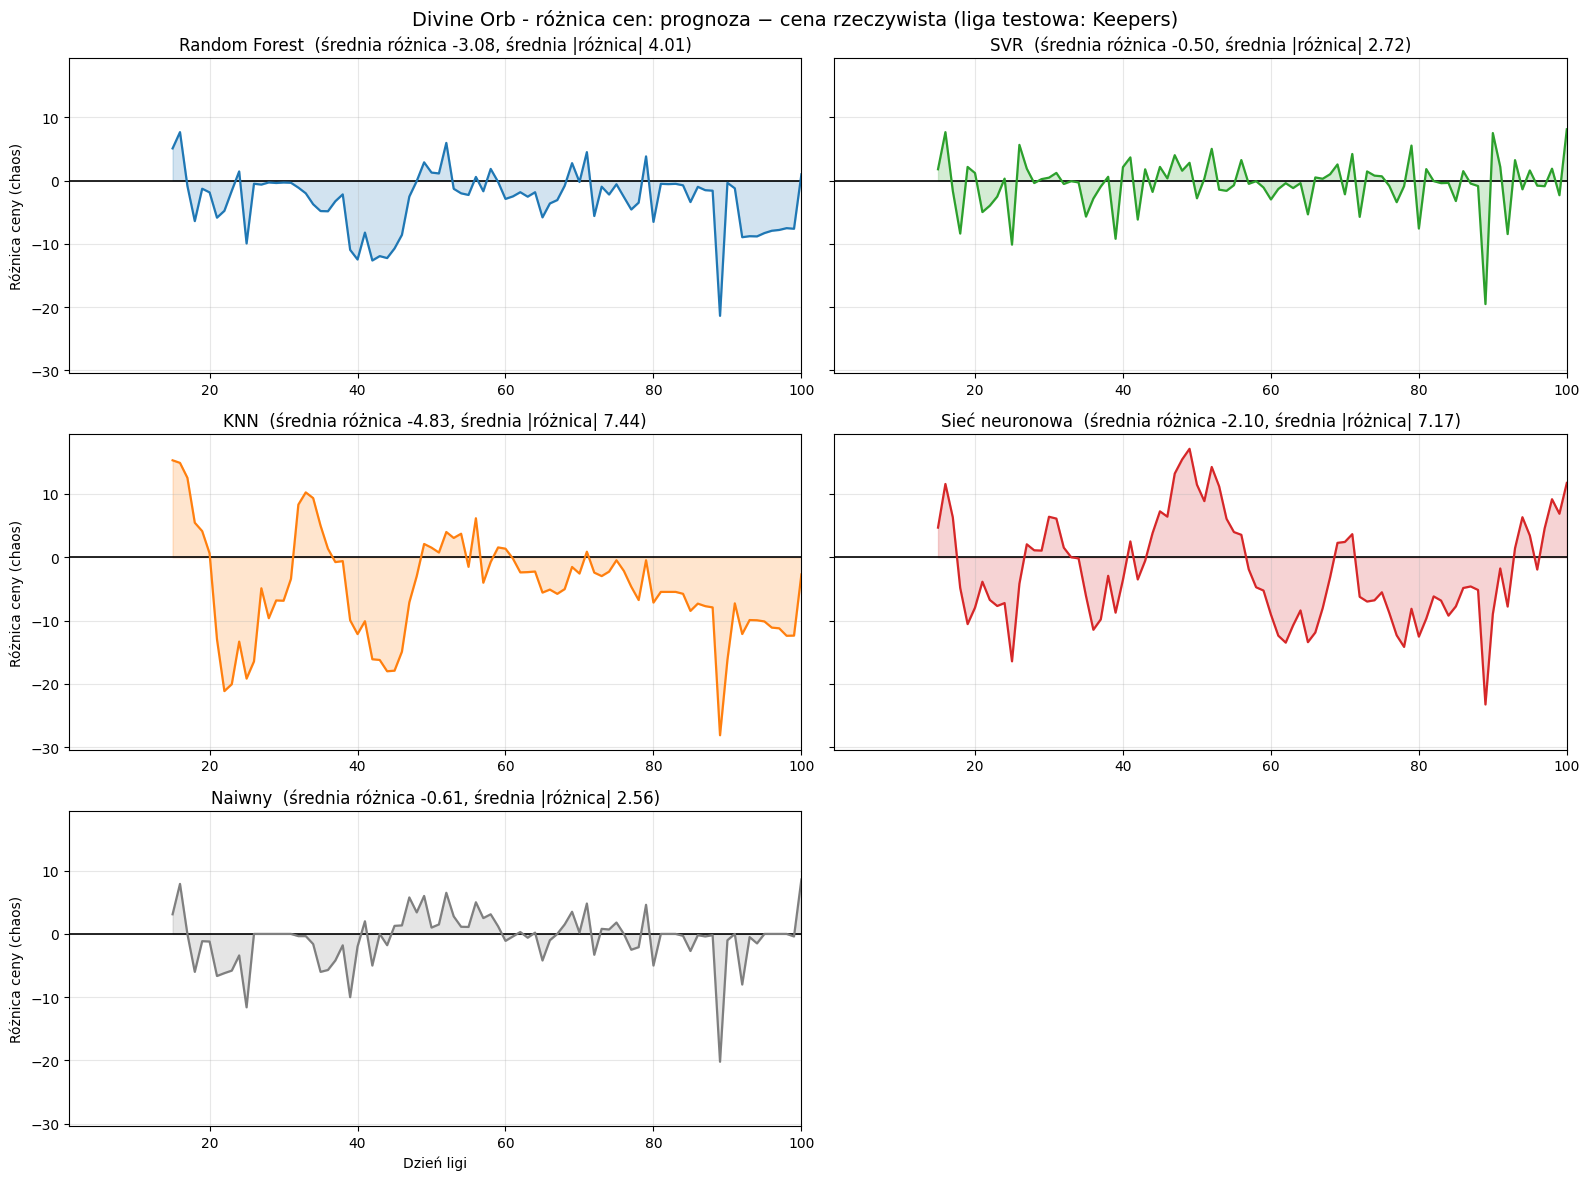

In [17]:
import os

EXPORT_DIR = 'plots'            # folder for the exported files
EXPORT_FORMATS = ['png', 'pdf'] # add 'svg' if you want
EXPORT_DPI = 300
os.makedirs(EXPORT_DIR, exist_ok=True)


def export_figure(fig, name):
    for ext in EXPORT_FORMATS:
        path = os.path.join(EXPORT_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
        print(f'Zapisano: {path}')


full_price = raw_test.values                 # cała seria, wraz z oknem startowym
days_full = np.arange(1, len(full_price) + 1)
days_pred = np.array(days_preds)             # dni, dla których istnieje prognoza

model_colors = {'Random Forest': 'tab:blue', 'SVR': 'tab:green', 'KNN': 'tab:orange',
                'Sieć neuronowa': 'tab:red', 'Naiwny': 'tab:gray'}
names = list(preds_all.keys())
ncols = 2
nrows = int(np.ceil(len(names) / ncols))
file_tag = f"{ITEM.replace(' ', '_')}_{league_names[test_idx]}"

# 1) cena rzeczywista vs prognoza - osobny wykres dla każdego modelu
fig1, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows),
                          sharex=False, sharey=True, squeeze=False)
axes = axes.ravel()

for ax, name in zip(axes, names):
    preds = preds_all[name]
    m = results[name]
    color = model_colors.get(name, 'tab:purple')
    ax.axvspan(1, WINDOW, color='gray', alpha=0.12)
    ax.plot(days_full, full_price, color='black', lw=2, label='Rzeczywista cena')
    ax.plot(days_pred, preds, color=color, lw=1.8, label=f'Prognoza: {name}')
    ax.fill_between(days_pred, actuals_test, preds, color=color, alpha=0.15)
    ax.set_title(f"{name}  (MAE {m['MAE']:.2f}, MAPE {m['MAPE']:.1f}%, R² {m['R2']:.3f})",
                 fontsize=12)
    ax.set_xlim(1, len(full_price))
    ax.grid(alpha=0.3)
    ax.legend(loc='best')

for ax in axes[len(names):]:
    ax.set_visible(False)
for ax in axes[::ncols]:
    ax.set_ylabel('Cena (chaos)')
for ax in axes[-ncols:]:
    ax.set_xlabel('Dzień ligi')

fig1.suptitle(f'{ITEM} - cena rzeczywista vs. prognozy modeli '
              f'(liga testowa: {league_names[test_idx]}; szare tło = okno startowe)',
              fontsize=14)
plt.tight_layout()
export_figure(fig1, f'{file_tag}_cena_vs_modele')
plt.show()

# 2) różnica cen: prognoza - cena rzeczywista (>0 zawyżenie, <0 zaniżenie)
fig2, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows),
                          sharex=False, sharey=True, squeeze=False)
axes = axes.ravel()

for ax, name in zip(axes, names):
    diff = preds_all[name] - actuals_test
    color = model_colors.get(name, 'tab:purple')
    ax.axhline(0, color='black', lw=1.2)
    ax.plot(days_pred, diff, color=color, lw=1.6)
    ax.fill_between(days_pred, 0, diff, color=color, alpha=0.2)
    ax.set_title(f"{name}  (średnia różnica {diff.mean():+.2f}, "
                 f"średnia |różnica| {np.abs(diff).mean():.2f})", fontsize=12)
    ax.set_xlim(1, len(full_price))
    ax.grid(alpha=0.3)

for ax in axes[len(names):]:
    ax.set_visible(False)
for ax in axes[::ncols]:
    ax.set_ylabel('Różnica ceny (chaos)')
for ax in axes[-ncols:]:
    ax.set_xlabel('Dzień ligi')

fig2.suptitle(f'{ITEM} - różnica cen: prognoza − cena rzeczywista '
              f'(liga testowa: {league_names[test_idx]})', fontsize=14)
plt.tight_layout()
export_figure(fig2, f'{file_tag}_roznica_cen')
plt.show()

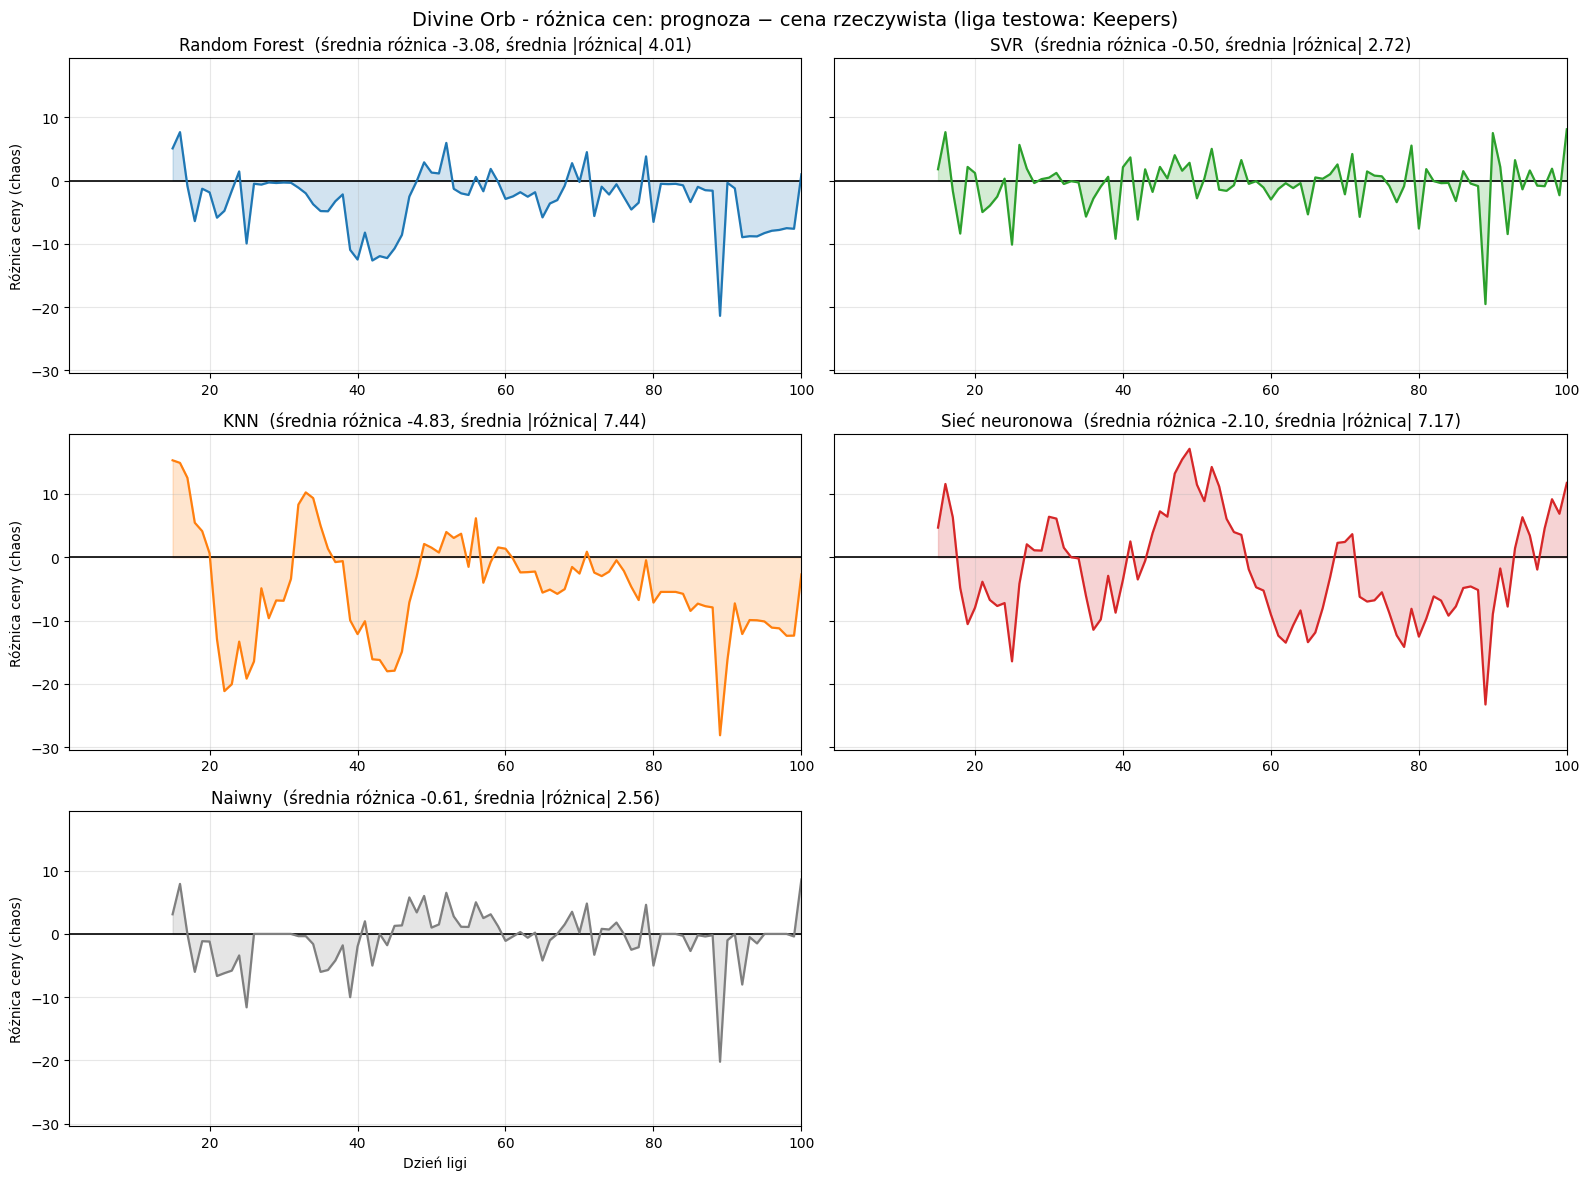

In [16]:
# 2) różnica cen: prognoza - cena rzeczywista (>0 zawyżenie, <0 zaniżenie)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows),
                         sharex=False, sharey=True, squeeze=False)
axes = axes.ravel()

for ax, name in zip(axes, names):
    diff = preds_all[name] - actuals_test
    color = model_colors.get(name, 'tab:purple')
    ax.axhline(0, color='black', lw=1.2)
    ax.plot(days_pred, diff, color=color, lw=1.6)
    ax.fill_between(days_pred, 0, diff, color=color, alpha=0.2)
    ax.set_title(f"{name}  (średnia różnica {diff.mean():+.2f}, "
                 f"średnia |różnica| {np.abs(diff).mean():.2f})", fontsize=12)
    ax.set_xlim(1, len(full_price))
    ax.grid(alpha=0.3)

for ax in axes[len(names):]:
    ax.set_visible(False)
for ax in axes[:len(names)]:
    ax.tick_params(labelbottom=True)
for ax in axes[::ncols]:
    ax.set_ylabel('Różnica ceny (chaos)')
for ax in axes[-ncols:]:
    ax.set_xlabel('Dzień ligi')

fig.suptitle(f'{ITEM} - różnica cen: prognoza − cena rzeczywista '
             f'(liga testowa: {league_names[test_idx]})', fontsize=14)
plt.tight_layout()
plt.show()

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Random_Forest_cena.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Random_Forest_cena.pdf


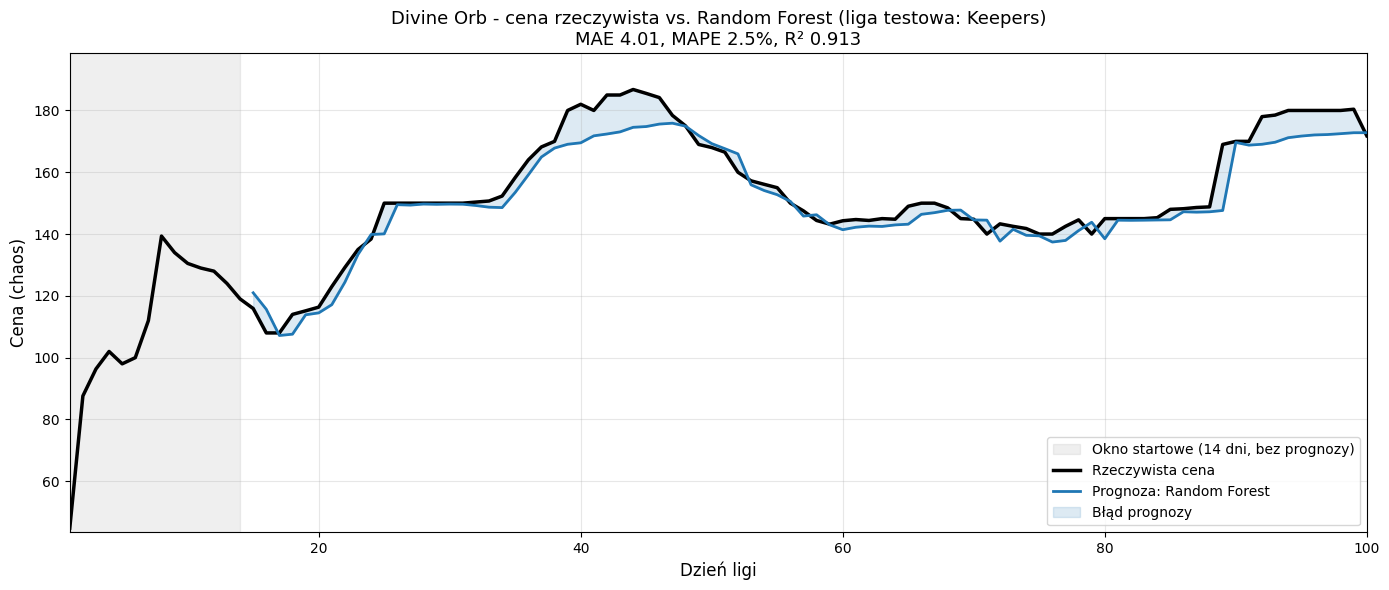

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Random_Forest_roznica.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Random_Forest_roznica.pdf


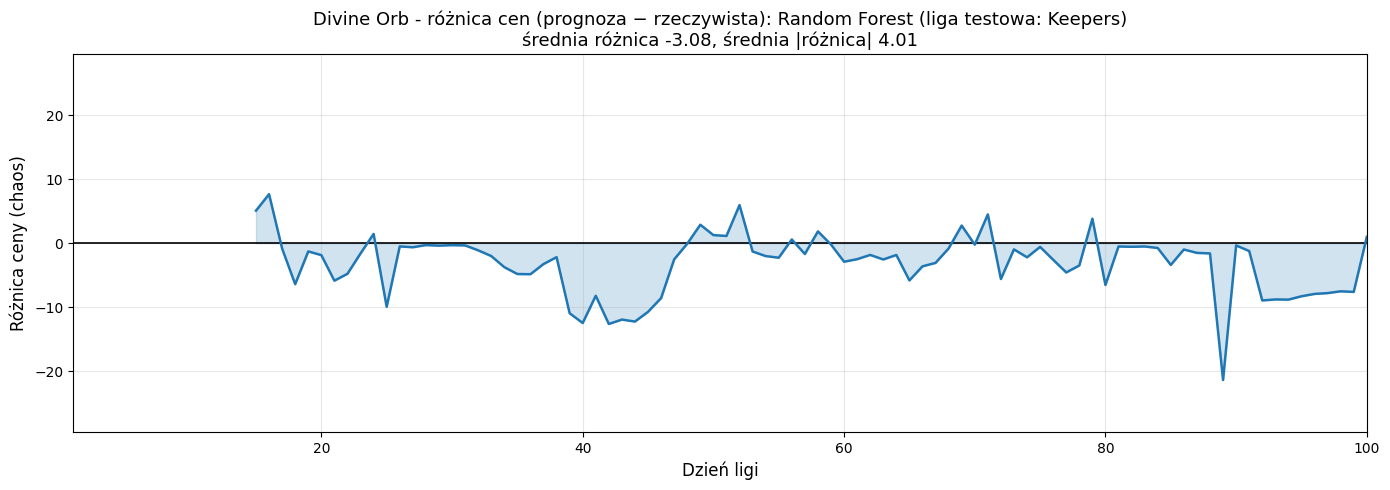

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_SVR_cena.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_SVR_cena.pdf


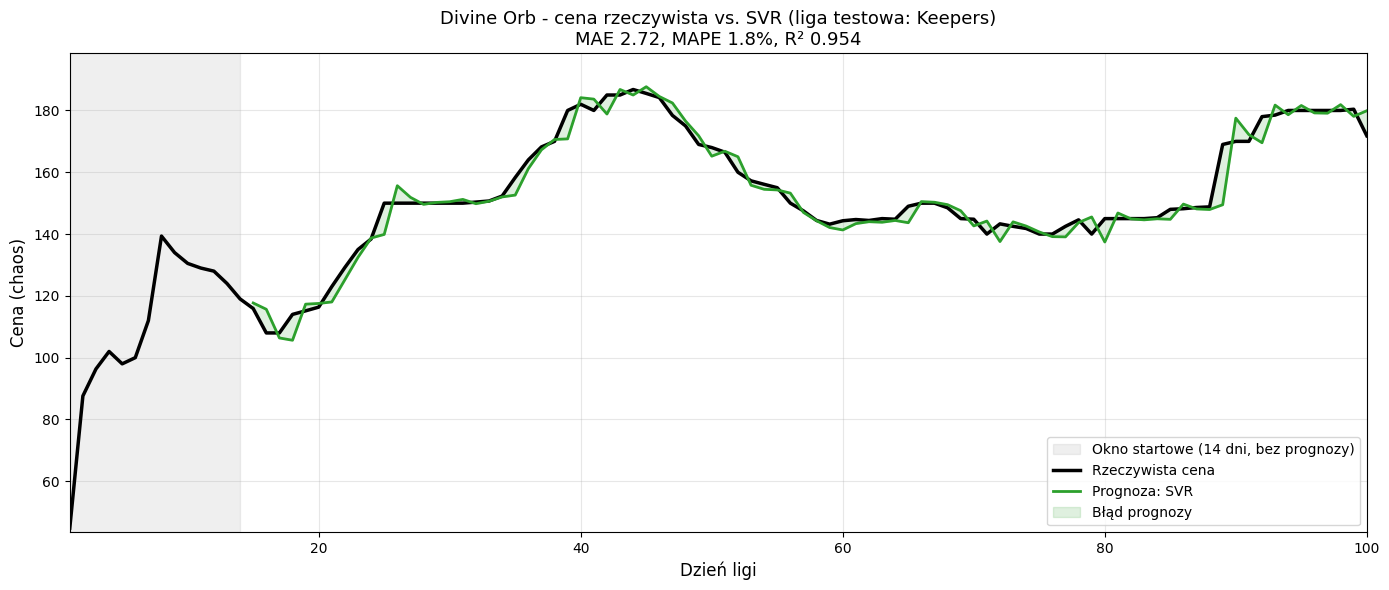

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_SVR_roznica.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_SVR_roznica.pdf


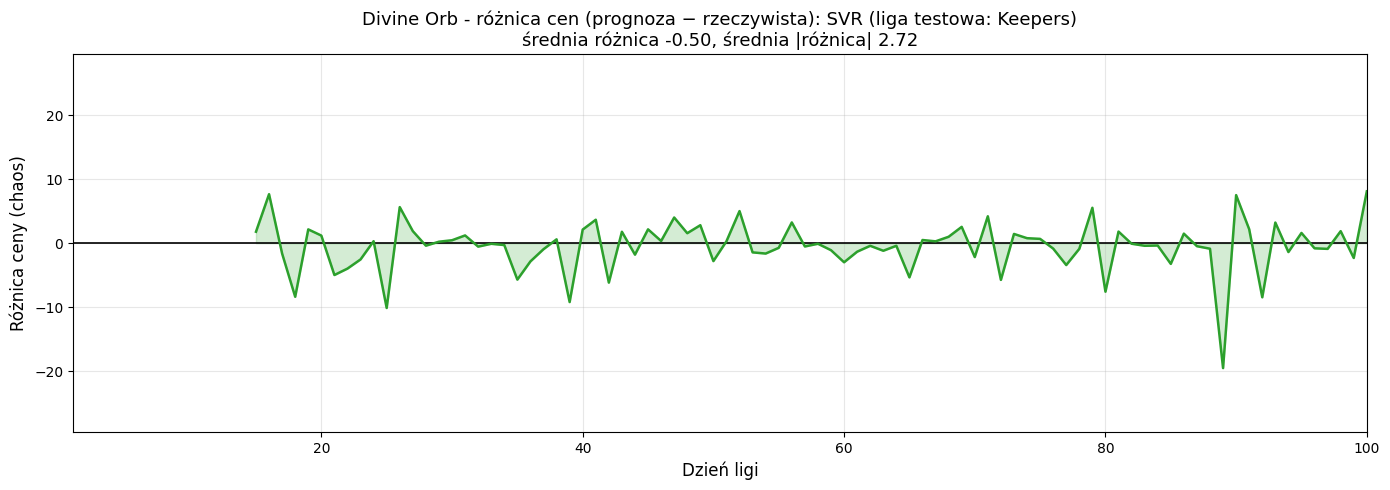

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_KNN_cena.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_KNN_cena.pdf


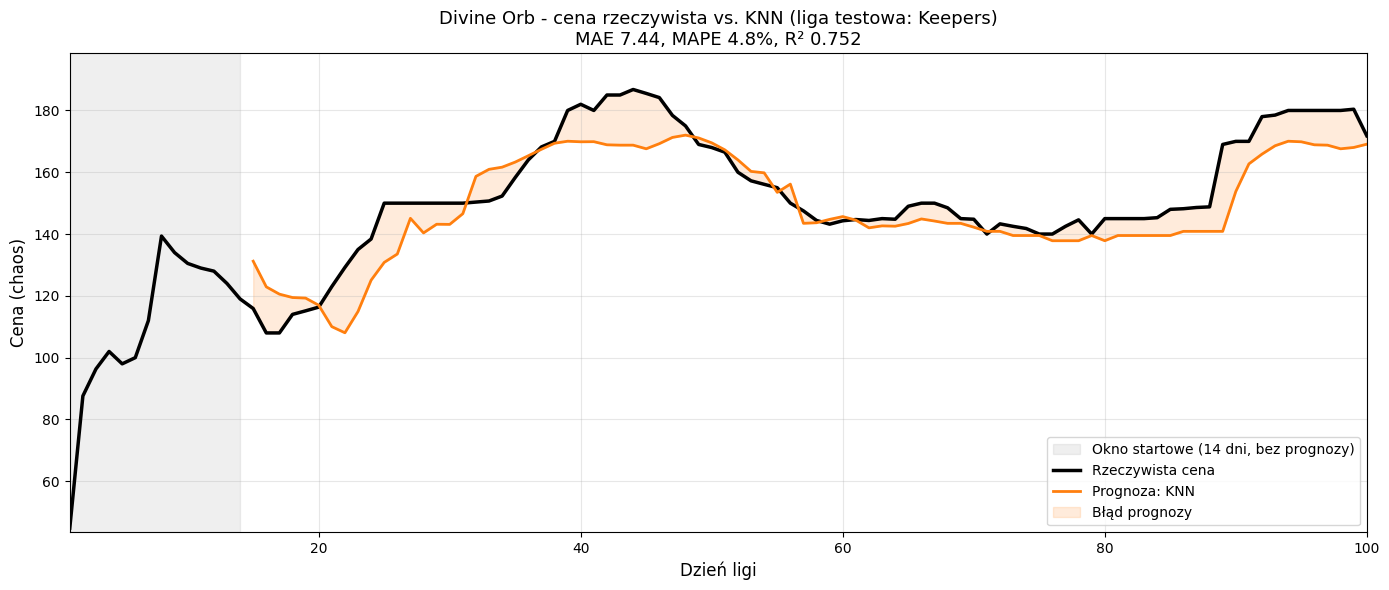

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_KNN_roznica.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_KNN_roznica.pdf


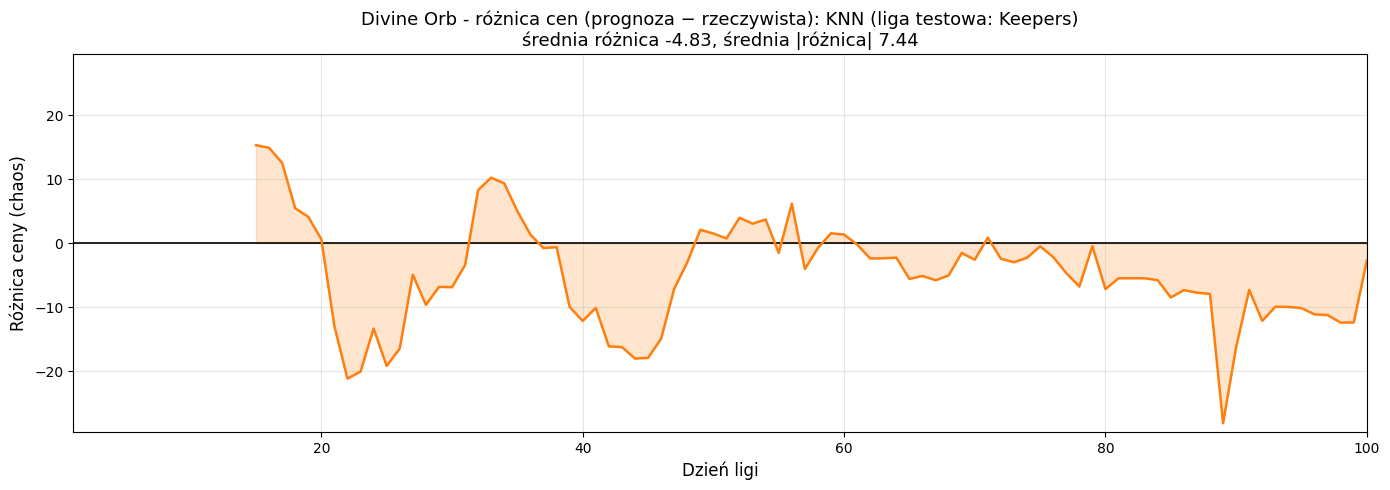

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Siec_neuronowa_cena.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Siec_neuronowa_cena.pdf


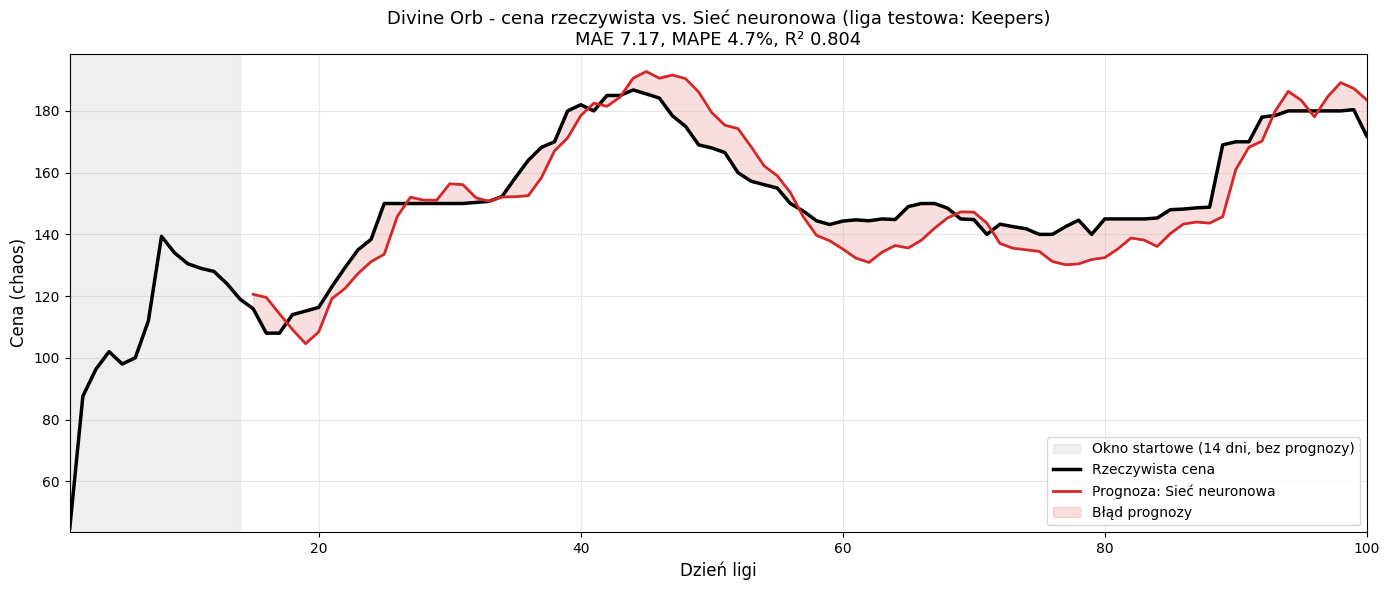

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Siec_neuronowa_roznica.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Siec_neuronowa_roznica.pdf


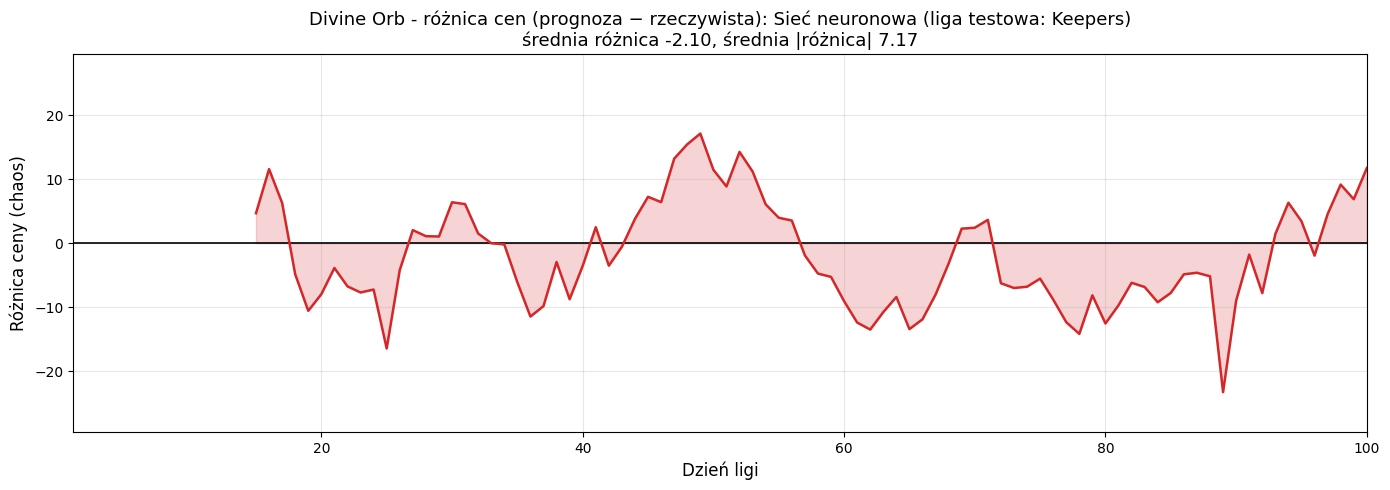

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Naiwny_cena.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Naiwny_cena.pdf


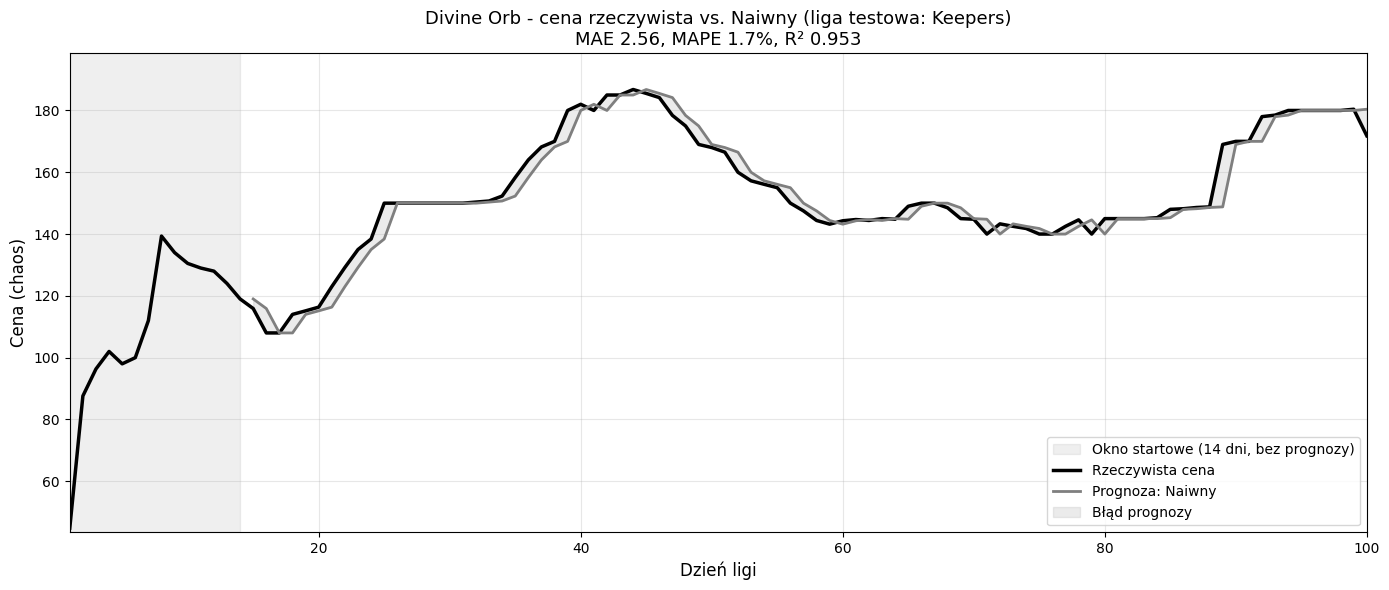

Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Naiwny_roznica.png
Zapisano: plots/pojedyncze/Divine_Orb_Keepers_Naiwny_roznica.pdf


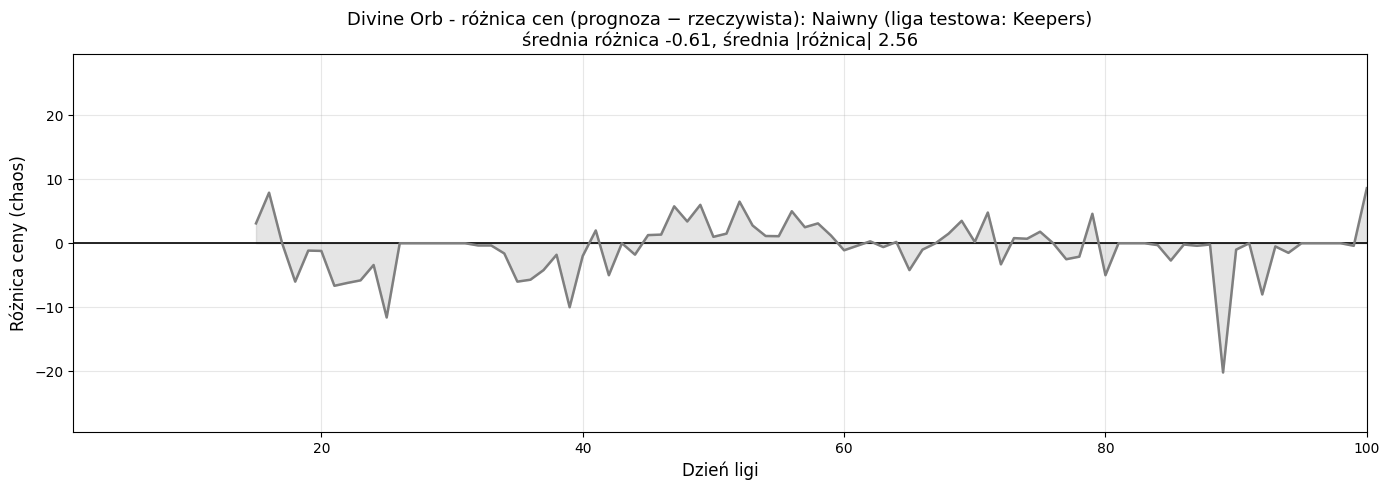

In [18]:
import os
import re
import unicodedata

EXPORT_DIR = 'plots/pojedyncze'   # folder na pojedyncze wykresy
EXPORT_FORMATS = ['png', 'pdf']   # dodaj 'svg' jeśli potrzebujesz
EXPORT_DPI = 300
SHOW_PLOTS = True                 # False = tylko zapis do plików, bez wyświetlania
os.makedirs(EXPORT_DIR, exist_ok=True)


def slug(text):
    text = text.replace('ł', 'l').replace('Ł', 'L')
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


def export_figure(fig, name):
    for ext in EXPORT_FORMATS:
        path = os.path.join(EXPORT_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
        print(f'Zapisano: {path}')


full_price = raw_test.values
days_full = np.arange(1, len(full_price) + 1)
days_pred = np.array(days_preds)

model_colors = {'Random Forest': 'tab:blue', 'SVR': 'tab:green', 'KNN': 'tab:orange',
                'Sieć neuronowa': 'tab:red', 'Naiwny': 'tab:gray'}
file_tag = f"{slug(ITEM)}_{slug(league_names[test_idx])}"

# wspólne zakresy osi Y, żeby wykresy różnych modeli były porównywalne
all_preds = np.concatenate([full_price] + list(preds_all.values()))
price_ylim = (all_preds.min() * 0.97, all_preds.max() * 1.03)
max_abs_diff = max(np.abs(p - actuals_test).max() for p in preds_all.values())
diff_ylim = (-max_abs_diff * 1.05, max_abs_diff * 1.05)

for name, preds in preds_all.items():
    color = model_colors.get(name, 'tab:purple')
    m = results[name]
    model_tag = f"{file_tag}_{slug(name)}"

    # 1) cena rzeczywista vs prognoza modelu
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(1, WINDOW, color='gray', alpha=0.12,
               label=f'Okno startowe ({WINDOW} dni, bez prognozy)')
    ax.plot(days_full, full_price, color='black', lw=2.5, label='Rzeczywista cena')
    ax.plot(days_pred, preds, color=color, lw=2, label=f'Prognoza: {name}')
    ax.fill_between(days_pred, actuals_test, preds, color=color, alpha=0.15,
                    label='Błąd prognozy')
    ax.set_title(f"{ITEM} - cena rzeczywista vs. {name} (liga testowa: "
                 f"{league_names[test_idx]})\n"
                 f"MAE {m['MAE']:.2f}, MAPE {m['MAPE']:.1f}%, R² {m['R2']:.3f}",
                 fontsize=13)
    ax.set_xlabel('Dzień ligi', fontsize=12)
    ax.set_ylabel('Cena (chaos)', fontsize=12)
    ax.set_xlim(1, len(full_price))
    ax.set_ylim(*price_ylim)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')
    plt.tight_layout()
    export_figure(fig, f'{model_tag}_cena')
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

    # 2) różnica cen: prognoza - cena rzeczywista (>0 zawyżenie, <0 zaniżenie)
    diff = preds - actuals_test
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.axhline(0, color='black', lw=1.2)
    ax.plot(days_pred, diff, color=color, lw=1.8)
    ax.fill_between(days_pred, 0, diff, color=color, alpha=0.2)
    ax.set_title(f"{ITEM} - różnica cen (prognoza − rzeczywista): {name} "
                 f"(liga testowa: {league_names[test_idx]})\n"
                 f"średnia różnica {diff.mean():+.2f}, "
                 f"średnia |różnica| {np.abs(diff).mean():.2f}",
                 fontsize=13)
    ax.set_xlabel('Dzień ligi', fontsize=12)
    ax.set_ylabel('Różnica ceny (chaos)', fontsize=12)
    ax.set_xlim(1, len(full_price))
    ax.set_ylim(*diff_ylim)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    export_figure(fig, f'{model_tag}_roznica')
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

Zapisano: plots/Divine_Orb_Keepers_zbiorczy_cena.png
Zapisano: plots/Divine_Orb_Keepers_zbiorczy_cena.pdf


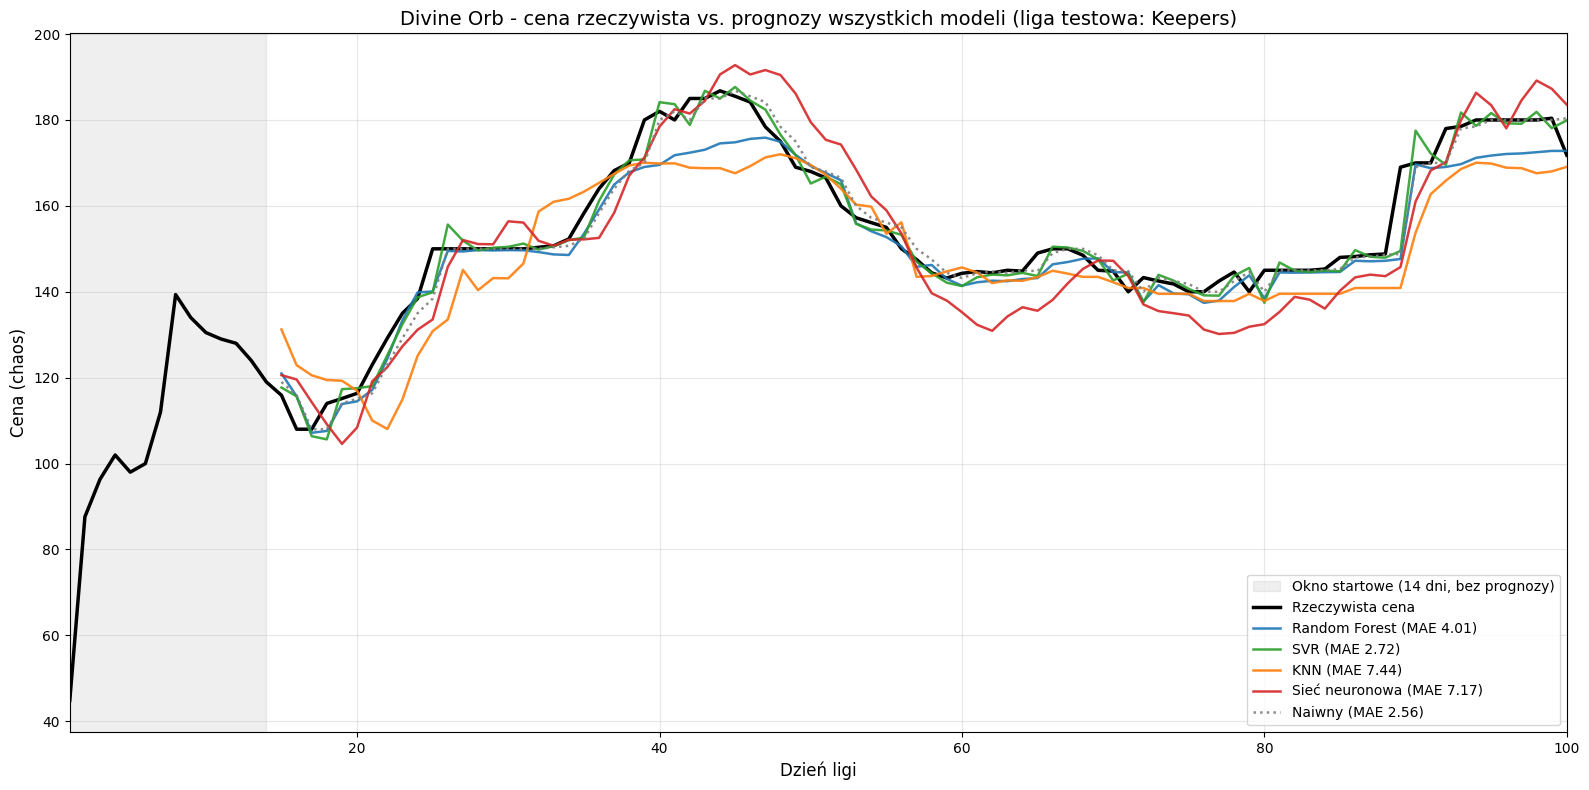

Zapisano: plots/Divine_Orb_Keepers_zbiorczy_roznica.png
Zapisano: plots/Divine_Orb_Keepers_zbiorczy_roznica.pdf


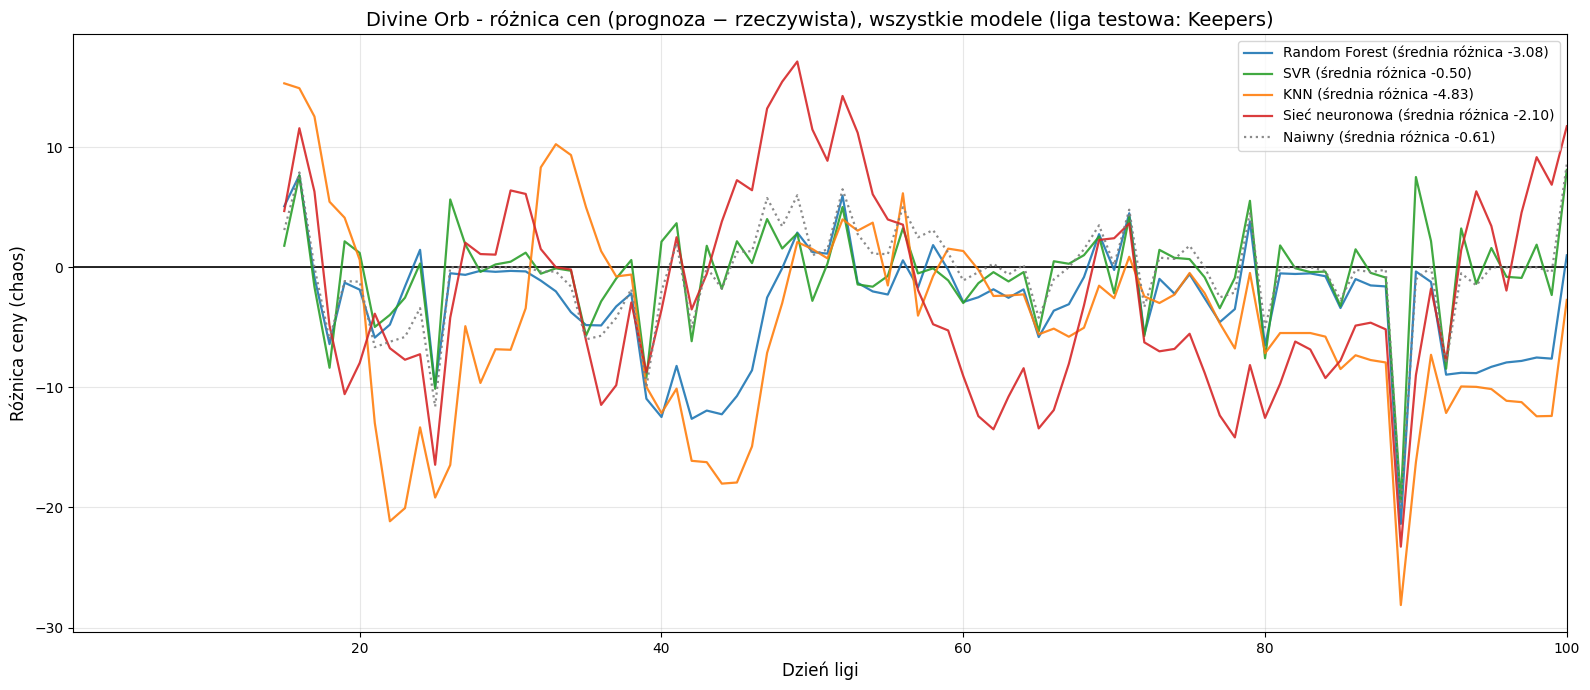

In [19]:
import os
import re
import unicodedata

EXPORT_DIR = 'plots'              # folder na wykresy zbiorcze
EXPORT_FORMATS = ['png', 'pdf']   # dodaj 'svg' jeśli potrzebujesz
EXPORT_DPI = 300
SHOW_PLOTS = True
os.makedirs(EXPORT_DIR, exist_ok=True)


def slug(text):
    text = text.replace('ł', 'l').replace('Ł', 'L')
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


def export_figure(fig, name):
    for ext in EXPORT_FORMATS:
        path = os.path.join(EXPORT_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
        print(f'Zapisano: {path}')


full_price = raw_test.values
days_full = np.arange(1, len(full_price) + 1)
days_pred = np.array(days_preds)

# te same kolory co na wykresach pojedynczych i panelowych
model_colors = {'Random Forest': 'tab:blue', 'SVR': 'tab:green', 'KNN': 'tab:orange',
                'Sieć neuronowa': 'tab:red', 'Naiwny': 'tab:gray'}
# model naiwny jako punkt odniesienia: linia kropkowana
model_linestyles = {'Naiwny': ':'}
file_tag = f"{slug(ITEM)}_{slug(league_names[test_idx])}"


def line_kwargs(name, lw=1.8):
    return dict(color=model_colors.get(name, 'tab:purple'),
                linestyle=model_linestyles.get(name, '-'),
                lw=lw, alpha=0.9)


# 1) zbiorczy: cena rzeczywista vs wszystkie modele
fig, ax = plt.subplots(figsize=(16, 8))
ax.axvspan(1, WINDOW, color='gray', alpha=0.12,
           label=f'Okno startowe ({WINDOW} dni, bez prognozy)')
ax.plot(days_full, full_price, color='black', lw=2.5, label='Rzeczywista cena')
for name, preds in preds_all.items():
    ax.plot(days_pred, preds, label=f"{name} (MAE {results[name]['MAE']:.2f})",
            **line_kwargs(name))
ax.set_title(f'{ITEM} - cena rzeczywista vs. prognozy wszystkich modeli '
             f'(liga testowa: {league_names[test_idx]})', fontsize=14)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena (chaos)', fontsize=12)
ax.set_xlim(1, len(full_price))
ax.grid(alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
export_figure(fig, f'{file_tag}_zbiorczy_cena')
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

# 2) zbiorczy: różnica cen (prognoza - rzeczywista) dla wszystkich modeli
fig, ax = plt.subplots(figsize=(16, 7))
ax.axhline(0, color='black', lw=1.2)
for name, preds in preds_all.items():
    diff = preds - actuals_test
    ax.plot(days_pred, diff,
            label=f"{name} (średnia różnica {diff.mean():+.2f})",
            **line_kwargs(name, lw=1.6))
ax.set_title(f'{ITEM} - różnica cen (prognoza − rzeczywista), wszystkie modele '
             f'(liga testowa: {league_names[test_idx]})', fontsize=14)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Różnica ceny (chaos)', fontsize=12)
ax.set_xlim(1, len(full_price))
ax.grid(alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
export_figure(fig, f'{file_tag}_zbiorczy_roznica')
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

Ceny Divine Orb w chaosach - podsumowanie lig:
                  count     min      25%      50%     mean      75%      max     std
Necropolis     100.0000 38.0000 106.7900 123.9900 122.9700 137.0000 173.8000 19.9500
Affliction     100.0000 39.5000 139.5000 150.0000 165.9300 211.6700 215.0000 38.5800
Settlers       100.0000 58.2000 136.5000 150.0000 146.1800 160.0800 176.9700 21.1100
Mercenaries    100.0000 55.3000 140.4500 151.5000 165.2000 199.5500 227.9200 31.4600
Keepers (test) 100.0000 44.8500 140.0000 148.3500 147.7200 168.0500 186.7900 24.9900
Zapisano: plots/Divine_Orb_zbior_treningowy_ceny.png
Zapisano: plots/Divine_Orb_zbior_treningowy_ceny.pdf


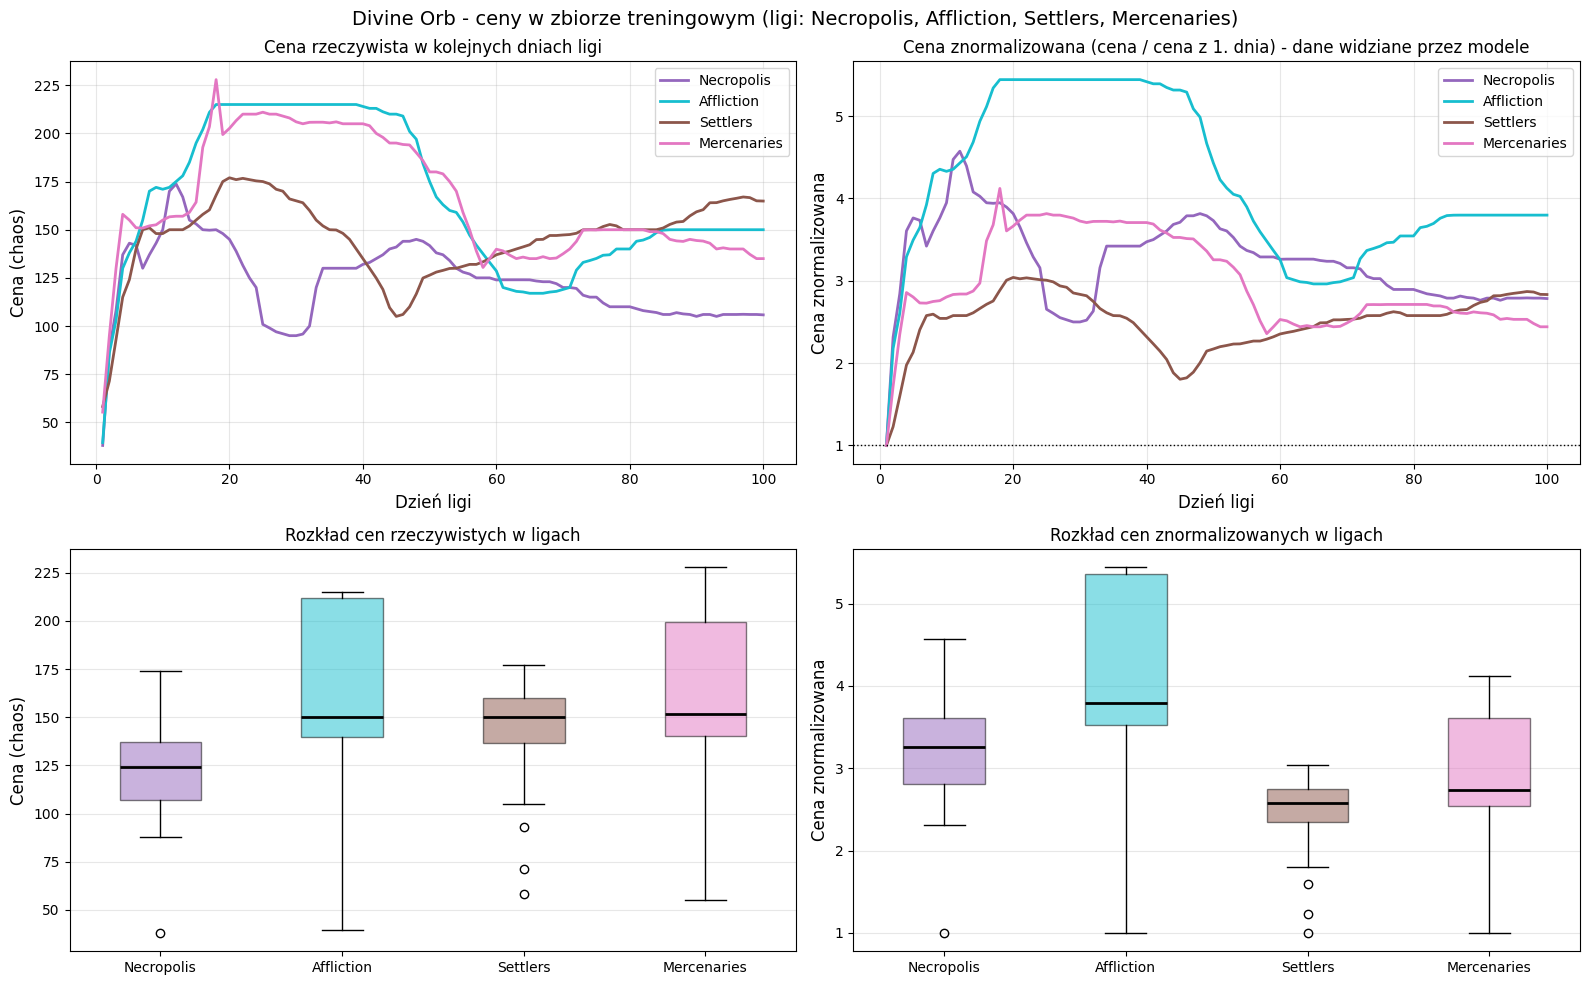

Zapisano: plots/Divine_Orb_zbior_testowy_ceny.png
Zapisano: plots/Divine_Orb_zbior_testowy_ceny.pdf


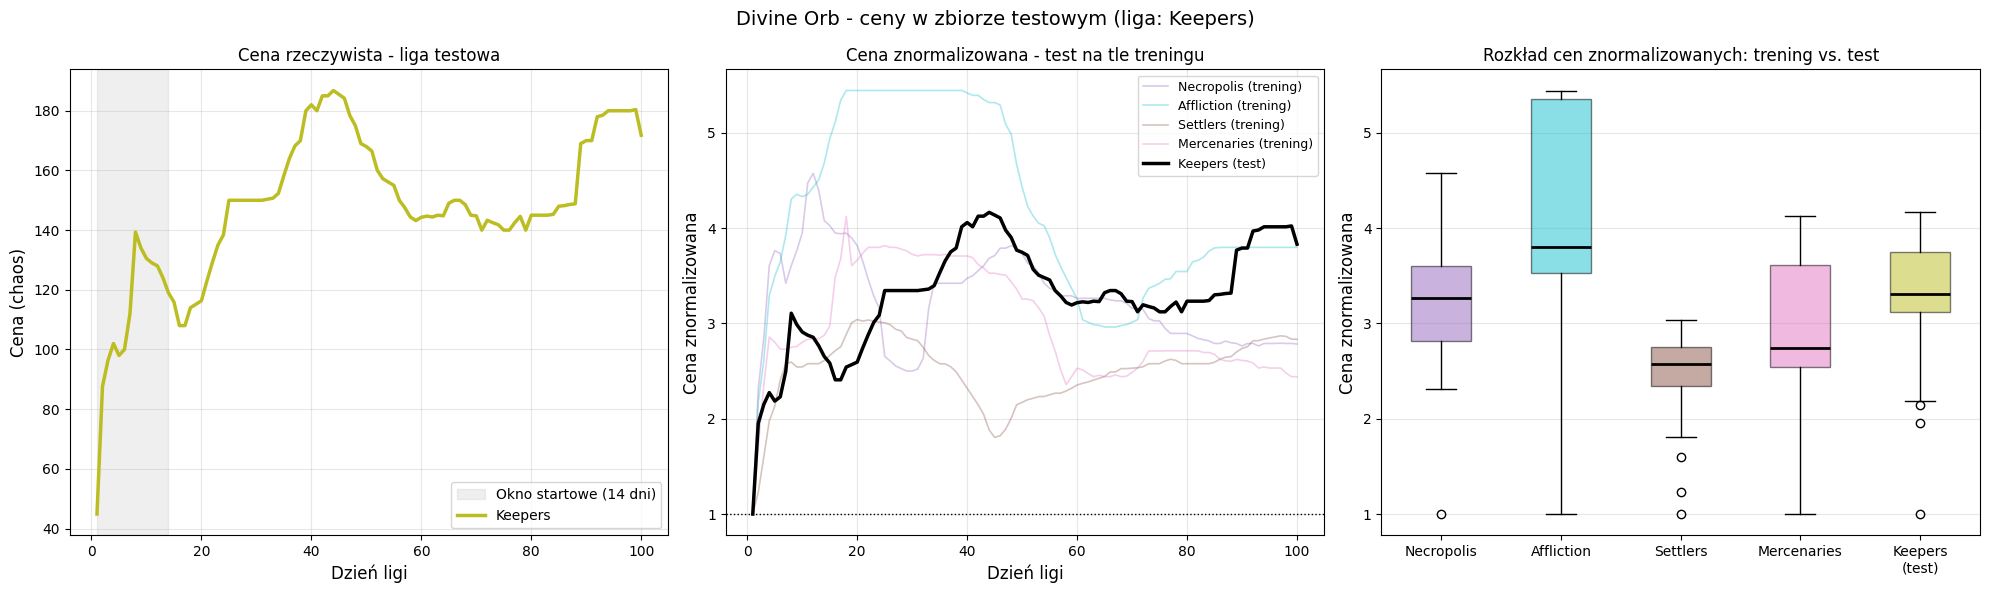

In [20]:
import os
import re
import unicodedata

EXPORT_DIR = 'plots'              # folder na wykresy
EXPORT_FORMATS = ['png', 'pdf']   # dodaj 'svg' jeśli potrzebujesz
EXPORT_DPI = 300
SHOW_PLOTS = True
os.makedirs(EXPORT_DIR, exist_ok=True)


def slug(text):
    text = text.replace('ł', 'l').replace('Ł', 'L')
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


def export_figure(fig, name):
    for ext in EXPORT_FORMATS:
        path = os.path.join(EXPORT_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
        print(f'Zapisano: {path}')


# stałe kolory lig (inne niż kolory modeli, żeby ich nie mylić)
league_palette = ['tab:purple', 'tab:cyan', 'tab:brown', 'tab:pink', 'tab:olive']
league_colors = {name: league_palette[i % len(league_palette)]
                 for i, name in enumerate(league_names)}
file_tag = slug(ITEM)

# zbieramy serie cen: zbiór treningowy (wszystkie ligi poza testową) i testowy
train_raw, train_norm = {}, {}
for i, df in enumerate(leagues):
    if i == test_idx or ITEM not in df.index:
        continue
    s = df.loc[ITEM].dropna()
    if s.iloc[0] == 0 or pd.isna(s.iloc[0]):
        continue
    train_raw[league_names[i]] = s
    train_norm[league_names[i]] = s / s.iloc[0]      # tak widzi to model

test_name = league_names[test_idx]
test_raw = leagues[test_idx].loc[ITEM].dropna()
test_norm = test_raw / test_raw.iloc[0]


def boxplot(ax, series_dict, colors, ylabel, title):
    names_ = list(series_dict.keys())
    bp = ax.boxplot([series_dict[n].values for n in names_], patch_artist=True,
                    showfliers=True, medianprops=dict(color='black', lw=2))
    for patch, n in zip(bp['boxes'], names_):
        patch.set_facecolor(colors[n])
        patch.set_alpha(0.5)
    ax.set_xticks(range(1, len(names_) + 1))
    ax.set_xticklabels(names_)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12)
    ax.grid(alpha=0.3, axis='y')


# podsumowanie liczbowe
summary = pd.DataFrame({n: s.describe() for n, s in
                        {**train_raw, f'{test_name} (test)': test_raw}.items()}).T
print(f'Ceny {ITEM} w chaosach - podsumowanie lig:')
print(summary[['count', 'min', '25%', '50%', 'mean', '75%', 'max', 'std']].round(2).to_string())

# 1) ZBIÓR TRENINGOWY - ceny w różnych ligach
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

ax = axes[0, 0]
for n, s in train_raw.items():
    ax.plot(s.index, s.values, color=league_colors[n], lw=2, label=n)
ax.set_title('Cena rzeczywista w kolejnych dniach ligi', fontsize=12)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena (chaos)', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best')

ax = axes[0, 1]
for n, s in train_norm.items():
    ax.plot(s.index, s.values, color=league_colors[n], lw=2, label=n)
ax.axhline(1, color='black', lw=1, linestyle=':')
ax.set_title('Cena znormalizowana (cena / cena z 1. dnia) - dane widziane przez modele',
             fontsize=12)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena znormalizowana', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best')

boxplot(axes[1, 0], train_raw, league_colors, 'Cena (chaos)',
        'Rozkład cen rzeczywistych w ligach')
boxplot(axes[1, 1], train_norm, league_colors, 'Cena znormalizowana',
        'Rozkład cen znormalizowanych w ligach')

fig.suptitle(f'{ITEM} - ceny w zbiorze treningowym (ligi: {", ".join(train_raw)})',
             fontsize=14)
plt.tight_layout()
export_figure(fig, f'{file_tag}_zbior_treningowy_ceny')
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

# 2) ZBIÓR TESTOWY - liga testowa na tle lig treningowych
color = league_colors[test_name]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ax = axes[0]
ax.axvspan(test_raw.index[0], test_raw.index[min(WINDOW, len(test_raw)) - 1],
           color='gray', alpha=0.12, label=f'Okno startowe ({WINDOW} dni)')
ax.plot(test_raw.index, test_raw.values, color=color, lw=2.5, label=test_name)
ax.set_title('Cena rzeczywista - liga testowa', fontsize=12)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena (chaos)', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best')

ax = axes[1]
for n, s in train_norm.items():
    ax.plot(s.index, s.values, color=league_colors[n], lw=1.2, alpha=0.35,
            label=f'{n} (trening)')
ax.plot(test_norm.index, test_norm.values, color='black', lw=2.5,
        label=f'{test_name} (test)')
ax.axhline(1, color='black', lw=1, linestyle=':')
ax.set_title('Cena znormalizowana - test na tle treningu', fontsize=12)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena znormalizowana', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best', fontsize=9)

all_norm = {**train_norm, f'{test_name}\n(test)': test_norm}
all_colors = {**league_colors, f'{test_name}\n(test)': color}
boxplot(axes[2], all_norm, all_colors, 'Cena znormalizowana',
        'Rozkład cen znormalizowanych: trening vs. test')

fig.suptitle(f'{ITEM} - ceny w zbiorze testowym (liga: {test_name})', fontsize=14)
plt.tight_layout()
export_figure(fig, f'{file_tag}_zbior_testowy_ceny')
if SHOW_PLOTS:
    plt.show()
plt.close(fig)

Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_cena_rzeczywista.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_cena_rzeczywista.pdf


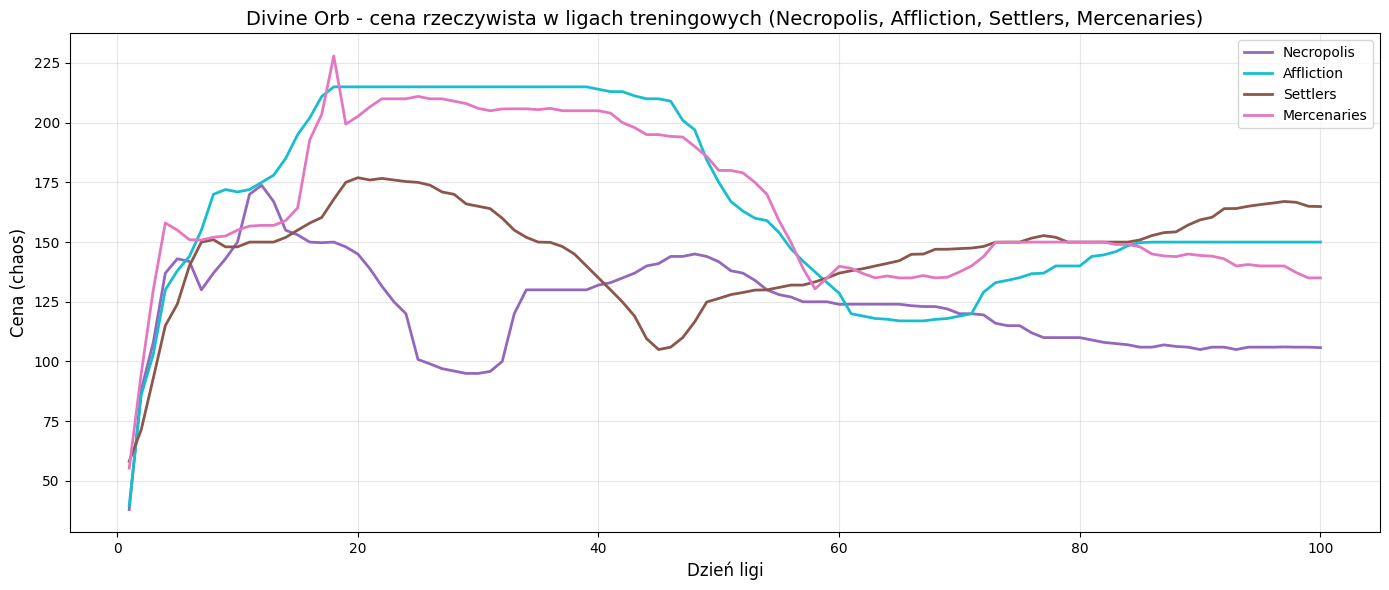

Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_cena_znormalizowana.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_cena_znormalizowana.pdf


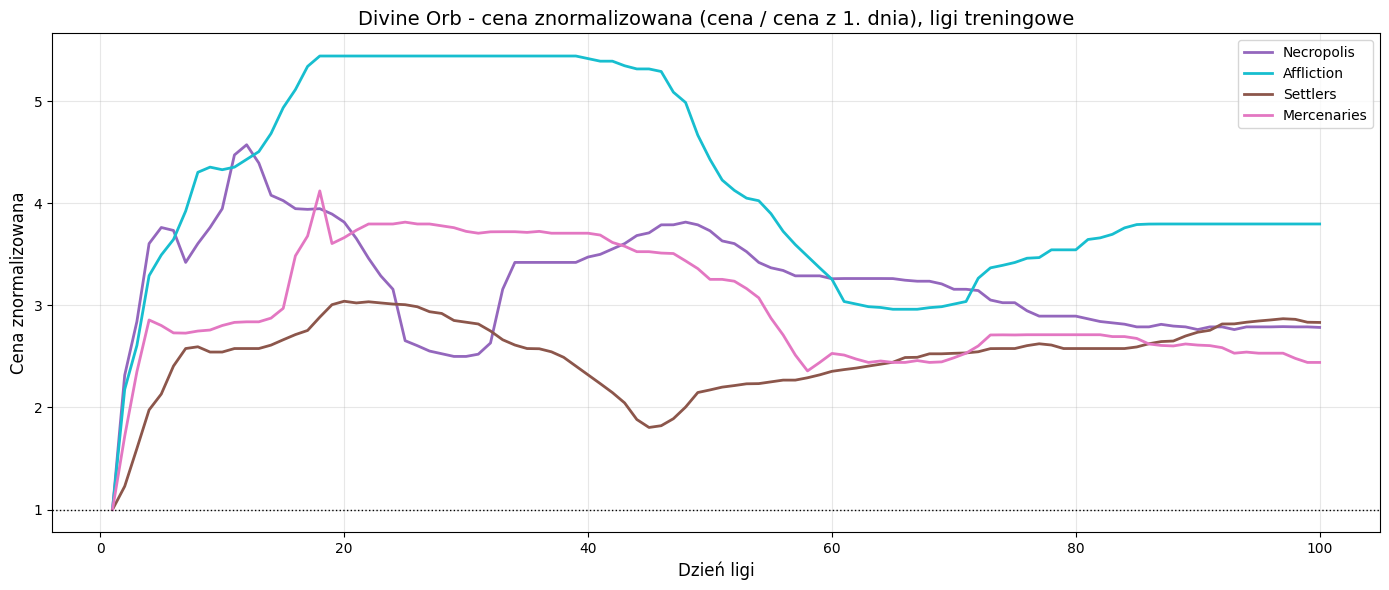

Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_rozklad_rzeczywisty.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_rozklad_rzeczywisty.pdf


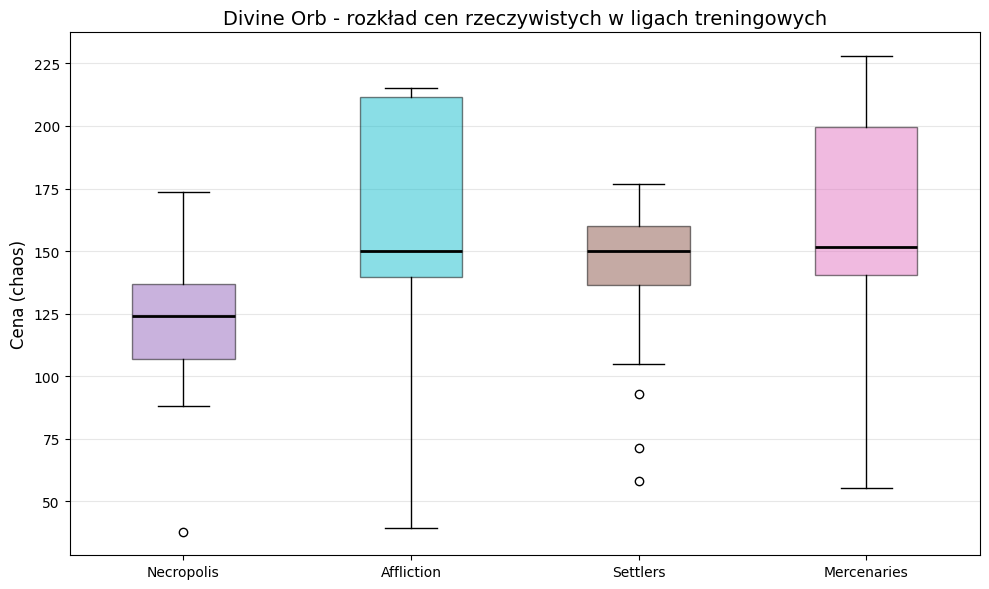

Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_rozklad_znormalizowany.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_trening_rozklad_znormalizowany.pdf


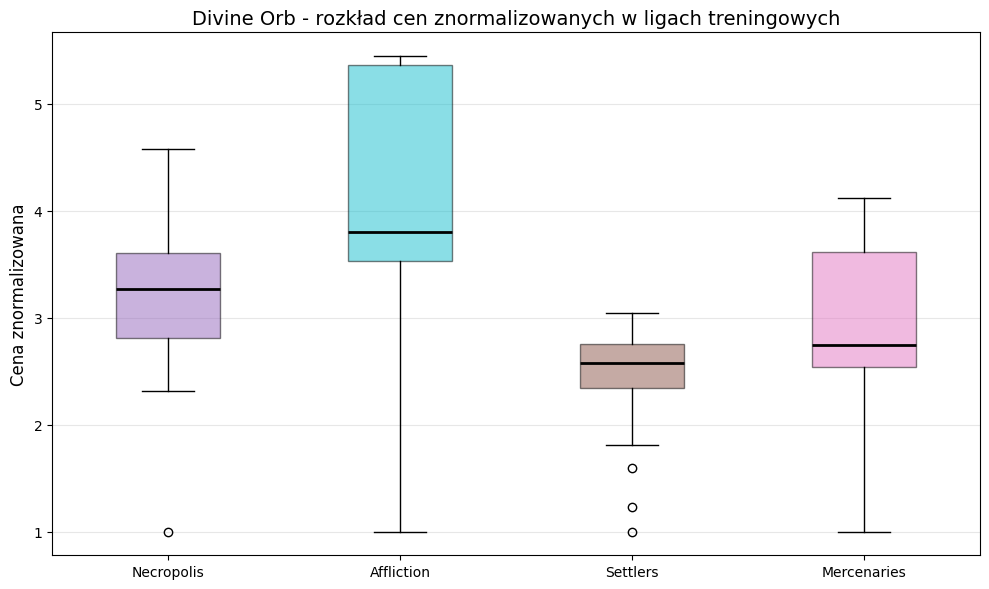

Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_cena_rzeczywista.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_cena_rzeczywista.pdf


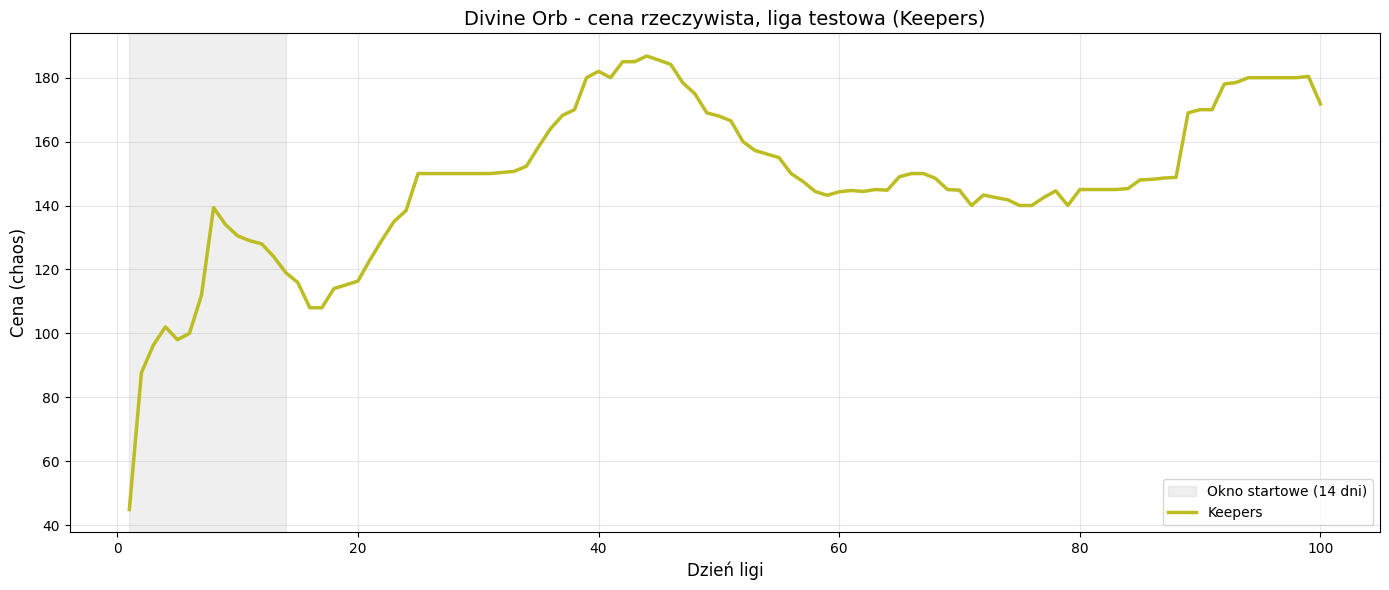

Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_cena_znormalizowana_na_tle_treningu.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_cena_znormalizowana_na_tle_treningu.pdf


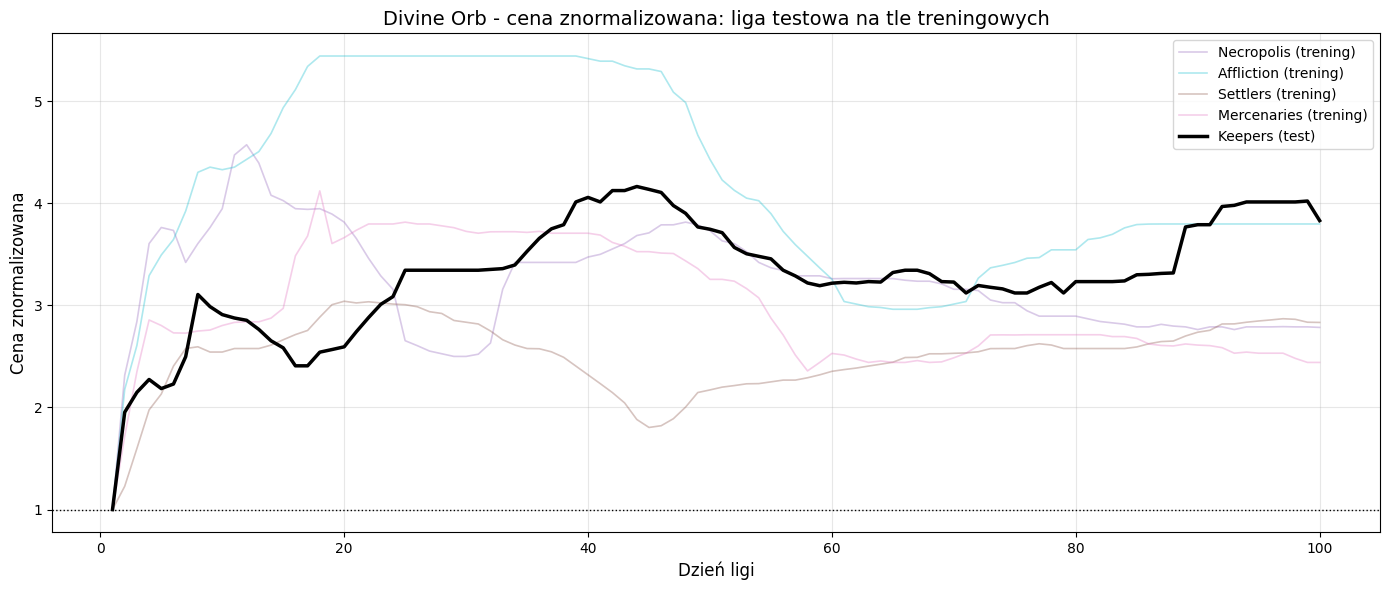

Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_rozklad_znormalizowany.png
Zapisano: plots/ceny_pojedyncze/Divine_Orb_test_rozklad_znormalizowany.pdf


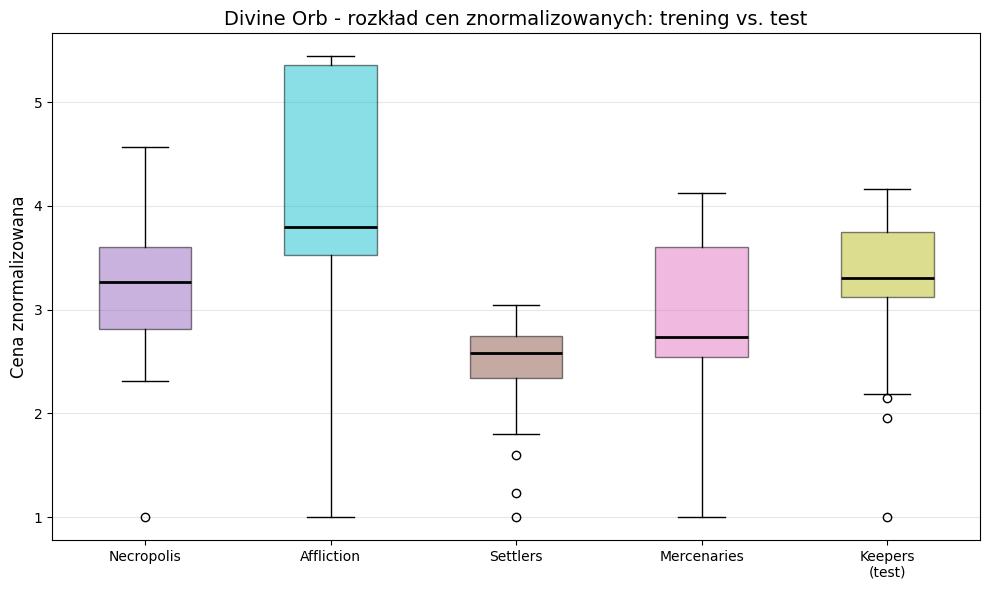

In [21]:
import os
import re
import unicodedata

EXPORT_DIR = 'plots/ceny_pojedyncze'   # folder na pojedyncze wykresy
EXPORT_FORMATS = ['png', 'pdf']        # dodaj 'svg' jeśli potrzebujesz
EXPORT_DPI = 300
SHOW_PLOTS = True                      # False = tylko zapis do plików
os.makedirs(EXPORT_DIR, exist_ok=True)


def slug(text):
    text = text.replace('ł', 'l').replace('Ł', 'L')
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


def finish(fig, name):
    """zapis do plików + opcjonalne wyświetlenie"""
    plt.tight_layout()
    for ext in EXPORT_FORMATS:
        path = os.path.join(EXPORT_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
        print(f'Zapisano: {path}')
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


# stałe kolory lig (inne niż kolory modeli, żeby ich nie mylić)
league_palette = ['tab:purple', 'tab:cyan', 'tab:brown', 'tab:pink', 'tab:olive']
league_colors = {name: league_palette[i % len(league_palette)]
                 for i, name in enumerate(league_names)}
file_tag = slug(ITEM)

# serie cen: zbiór treningowy (wszystkie ligi poza testową) i testowy
train_raw, train_norm = {}, {}
for i, df in enumerate(leagues):
    if i == test_idx or ITEM not in df.index:
        continue
    s = df.loc[ITEM].dropna()
    if s.iloc[0] == 0 or pd.isna(s.iloc[0]):
        continue
    train_raw[league_names[i]] = s
    train_norm[league_names[i]] = s / s.iloc[0]      # tak widzi to model

test_name = league_names[test_idx]
test_raw = leagues[test_idx].loc[ITEM].dropna()
test_norm = test_raw / test_raw.iloc[0]
train_label = ', '.join(train_raw)


def lines_plot(series_dict, ylabel, title, normalized=False):
    fig, ax = plt.subplots(figsize=(14, 6))
    for n, s in series_dict.items():
        ax.plot(s.index, s.values, color=league_colors[n], lw=2, label=n)
    if normalized:
        ax.axhline(1, color='black', lw=1, linestyle=':')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Dzień ligi', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')
    return fig


def box_plot(series_dict, colors, ylabel, title):
    fig, ax = plt.subplots(figsize=(10, 6))
    names_ = list(series_dict.keys())
    bp = ax.boxplot([series_dict[n].values for n in names_], patch_artist=True,
                    showfliers=True, medianprops=dict(color='black', lw=2))
    for patch, n in zip(bp['boxes'], names_):
        patch.set_facecolor(colors[n])
        patch.set_alpha(0.5)
    ax.set_xticks(range(1, len(names_) + 1))
    ax.set_xticklabels(names_)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.grid(alpha=0.3, axis='y')
    return fig


# ===================== ZBIÓR TRENINGOWY =====================
# 1) cena rzeczywista w kolejnych dniach lig
fig = lines_plot(train_raw, 'Cena (chaos)',
                 f'{ITEM} - cena rzeczywista w ligach treningowych ({train_label})')
finish(fig, f'{file_tag}_trening_cena_rzeczywista')

# 2) cena znormalizowana (dane widziane przez modele)
fig = lines_plot(train_norm, 'Cena znormalizowana',
                 f'{ITEM} - cena znormalizowana (cena / cena z 1. dnia), ligi treningowe',
                 normalized=True)
finish(fig, f'{file_tag}_trening_cena_znormalizowana')

# 3) rozkład cen rzeczywistych
fig = box_plot(train_raw, league_colors, 'Cena (chaos)',
               f'{ITEM} - rozkład cen rzeczywistych w ligach treningowych')
finish(fig, f'{file_tag}_trening_rozklad_rzeczywisty')

# 4) rozkład cen znormalizowanych
fig = box_plot(train_norm, league_colors, 'Cena znormalizowana',
               f'{ITEM} - rozkład cen znormalizowanych w ligach treningowych')
finish(fig, f'{file_tag}_trening_rozklad_znormalizowany')

# ===================== ZBIÓR TESTOWY =====================
color = league_colors[test_name]

# 5) cena rzeczywista ligi testowej
fig, ax = plt.subplots(figsize=(14, 6))
ax.axvspan(test_raw.index[0], test_raw.index[min(WINDOW, len(test_raw)) - 1],
           color='gray', alpha=0.12, label=f'Okno startowe ({WINDOW} dni)')
ax.plot(test_raw.index, test_raw.values, color=color, lw=2.5, label=test_name)
ax.set_title(f'{ITEM} - cena rzeczywista, liga testowa ({test_name})', fontsize=14)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena (chaos)', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best')
finish(fig, f'{file_tag}_test_cena_rzeczywista')

# 6) cena znormalizowana: test na tle treningu
fig, ax = plt.subplots(figsize=(14, 6))
for n, s in train_norm.items():
    ax.plot(s.index, s.values, color=league_colors[n], lw=1.2, alpha=0.35,
            label=f'{n} (trening)')
ax.plot(test_norm.index, test_norm.values, color='black', lw=2.5,
        label=f'{test_name} (test)')
ax.axhline(1, color='black', lw=1, linestyle=':')
ax.set_title(f'{ITEM} - cena znormalizowana: liga testowa na tle treningowych',
             fontsize=14)
ax.set_xlabel('Dzień ligi', fontsize=12)
ax.set_ylabel('Cena znormalizowana', fontsize=12)
ax.grid(alpha=0.3)
ax.legend(loc='best')
finish(fig, f'{file_tag}_test_cena_znormalizowana_na_tle_treningu')

# 7) rozkład cen znormalizowanych: trening vs test
all_norm = {**train_norm, f'{test_name}\n(test)': test_norm}
all_colors = {**league_colors, f'{test_name}\n(test)': color}
fig = box_plot(all_norm, all_colors, 'Cena znormalizowana',
               f'{ITEM} - rozkład cen znormalizowanych: trening vs. test')
finish(fig, f'{file_tag}_test_rozklad_znormalizowany')

Błąd w jednostkach znormalizowanych (cena / cena z 1. dnia):
                MAE trening  MAE CV  MAE test  test / trening  trening vs naiwny  test vs naiwny
Model                                                                                           
Naiwny               0.0450     NaN    0.0570          1.2680             1.0000          1.0000
Random Forest        0.0267  0.3297    0.0893          3.3449             0.5938          1.5664
SVR                  0.0389  0.0762    0.0606          1.5571             0.8655          1.0627
KNN                  0.0622  0.4218    0.1658          2.6666             1.3827          2.9078
Sieć neuronowa       0.1156     NaN    0.1598          1.3819             2.5714          2.8024


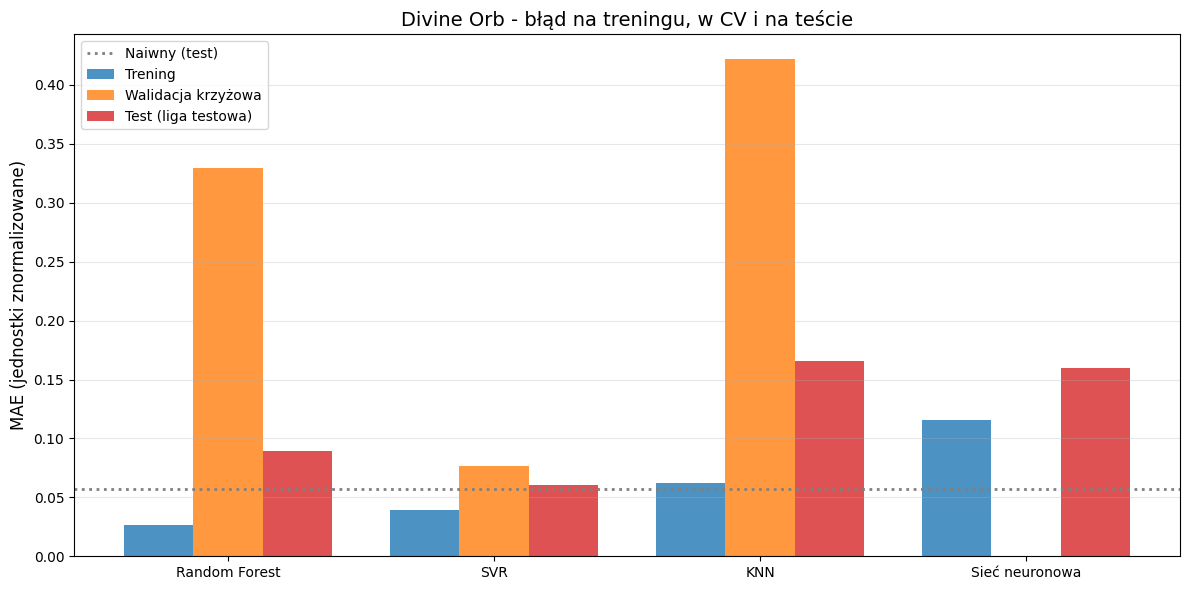

In [22]:
import os

EXPORT_DIR = 'plots'
EXPORT_FORMATS = ['png', 'pdf']
EXPORT_DPI = 300
os.makedirs(EXPORT_DIR, exist_ok=True)

# najlepsze modele po strojeniu + błąd walidacji krzyżowej (MAE, jednostki znormalizowane)
fitted_models = {
    'Random Forest': rf_grid.best_estimator_,
    'SVR': svr_grid.best_estimator_,
    'KNN': knn_grid.best_estimator_,
}
cv_mae = {
    'Random Forest': -rf_grid.best_score_,
    'SVR': -svr_grid.best_score_,
    'KNN': -knn_grid.best_score_,
}
if 'best_nn_model' in globals():
    fitted_models['Sieć neuronowa'] = best_nn_model
    cv_mae['Sieć neuronowa'] = np.nan      # sieć nie była oceniana przez CV


def predict_any(model, X):
    if hasattr(model, 'layers'):            # model Keras
        return model.predict(X, verbose=0).ravel()
    return np.asarray(model.predict(X)).ravel()


# wszystko w jednostkach znormalizowanych (cena / cena z 1. dnia), żeby trening i test były porównywalne
naive_tr_mae = mean_absolute_error(y_train, X_train[:, -1])
naive_te_mae = results['Naiwny']['MAE'] / base_price

rows = [{
    'Model': 'Naiwny', 'MAE trening': naive_tr_mae, 'MAE CV': np.nan,
    'MAE test': naive_te_mae, 'test / trening': naive_te_mae / naive_tr_mae,
    'trening vs naiwny': 1.0, 'test vs naiwny': 1.0,
}]
for name, model in fitted_models.items():
    tr_mae = mean_absolute_error(y_train, predict_any(model, X_train_standard))
    te_mae = results[name]['MAE'] / base_price
    rows.append({
        'Model': name, 'MAE trening': tr_mae, 'MAE CV': cv_mae[name],
        'MAE test': te_mae, 'test / trening': te_mae / tr_mae,
        'trening vs naiwny': tr_mae / naive_tr_mae,
        'test vs naiwny': te_mae / naive_te_mae,
    })

df_overfit = pd.DataFrame(rows).set_index('Model')
print('Błąd w jednostkach znormalizowanych (cena / cena z 1. dnia):')
print(df_overfit.round(4).to_string())

# wykres: trening vs walidacja krzyżowa vs test
plot_df = df_overfit.drop(index='Naiwny')[['MAE trening', 'MAE CV', 'MAE test']]
x = np.arange(len(plot_df))
w = 0.26
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - w, plot_df['MAE trening'], w, label='Trening', color='tab:blue', alpha=0.8)
ax.bar(x, plot_df['MAE CV'], w, label='Walidacja krzyżowa', color='tab:orange', alpha=0.8)
ax.bar(x + w, plot_df['MAE test'], w, label='Test (liga testowa)', color='tab:red', alpha=0.8)
ax.axhline(naive_te_mae, color='gray', linestyle=':', lw=2, label='Naiwny (test)')
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.set_ylabel('MAE (jednostki znormalizowane)', fontsize=12)
ax.set_title(f'{ITEM} - błąd na treningu, w CV i na teście', fontsize=14)
ax.grid(alpha=0.3, axis='y')
ax.legend(loc='best')
plt.tight_layout()
for ext in EXPORT_FORMATS:
    fig.savefig(os.path.join(EXPORT_DIR, f'{ITEM.replace(" ", "_")}_diagnoza_przeuczenia.{ext}'),
                dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
plt.show()

In [23]:
from sklearn.base import clone

# najlepsze hiperparametry z wcześniejszego strojenia (stałe), uczymy od nowa na każdym foldzie
lolo_models = {
    'Random Forest': rf_grid.best_estimator_,
    'SVR': svr_grid.best_estimator_,
    'KNN': knn_grid.best_estimator_,
}

league_windows = {}
for name_l, df_l in zip(league_names, leagues):
    if ITEM not in df_l.index:
        continue
    norm_l = normalize(df_l.loc[ITEM].dropna())
    if norm_l is None:
        continue
    league_windows[name_l] = make_windows(norm_l, WINDOW)

rows = []
for held_out in league_windows:
    others = [n for n in league_windows if n != held_out]
    X_tr = np.vstack([league_windows[n][0] for n in others])
    y_tr = np.concatenate([league_windows[n][1] for n in others])
    X_te, y_te = league_windows[held_out]
    sc = StandardScaler().fit(X_tr)

    row = {'Liga testowa': held_out,
           'Naiwny': mean_absolute_error(y_te, X_te[:, -1])}
    for mname, est in lolo_models.items():
        m_ = clone(est).fit(sc.transform(X_tr), y_tr)
        row[mname] = mean_absolute_error(y_te, m_.predict(sc.transform(X_te)))
    rows.append(row)

df_lolo = pd.DataFrame(rows).set_index('Liga testowa')
df_lolo.loc['Średnia'] = df_lolo.mean()

print('MAE (jednostki znormalizowane), każda liga po kolei jako testowa:')
print(df_lolo.round(4).to_string())
print('\nMAE względem modelu naiwnego (>1 = gorzej niż naiwny):')
print(df_lolo.div(df_lolo['Naiwny'], axis=0).round(2).to_string())

MAE (jednostki znormalizowane), każda liga po kolei jako testowa:
              Naiwny  Random Forest    SVR    KNN
Liga testowa                                     
Necropolis    0.0477         0.0492 0.0465 0.1504
Affliction    0.0474         0.5883 0.0532 0.7877
Settlers      0.0335         0.1235 0.0290 0.2038
Mercenaries   0.0513         0.0653 0.0518 0.1574
Keepers       0.0570         0.0893 0.0606 0.1658
Średnia       0.0474         0.1831 0.0482 0.2930

MAE względem modelu naiwnego (>1 = gorzej niż naiwny):
              Naiwny  Random Forest    SVR     KNN
Liga testowa                                      
Necropolis    1.0000         1.0300 0.9800  3.1500
Affliction    1.0000        12.4100 1.1200 16.6200
Settlers      1.0000         3.6800 0.8600  6.0800
Mercenaries   1.0000         1.2700 1.0100  3.0700
Keepers       1.0000         1.5700 1.0600  2.9100
Średnia       1.0000         3.8600 1.0200  6.1800


Liczba epok: 51, najlepsza epoka (min val_loss): 36
loss (trening): 0.21766, val_loss: 0.00166


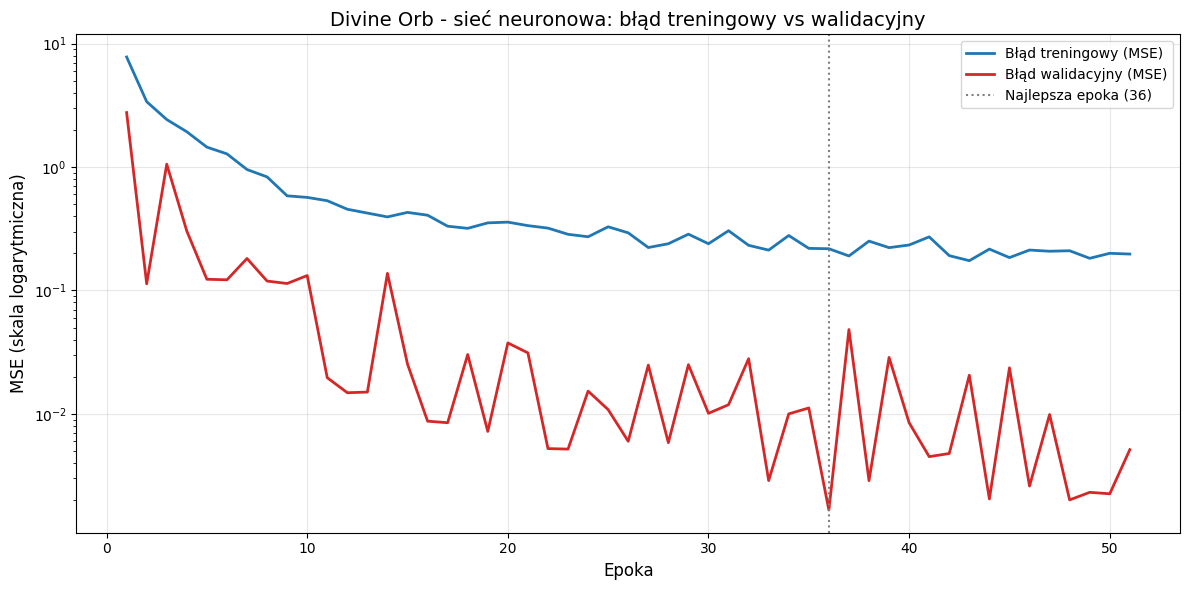

In [24]:
import os

# ponowny trening najlepszej konfiguracji sieci z zapisem historii uczenia
# (uwaga: bez ustalonego ziarna losowości przebieg będzie się nieco różnił od pierwotnego treningu)
clear_session()
cfg = best_nn_config
nn_check = build_nn_model(
    layers=cfg['layers'],
    activations=cfg.get('activations', 'relu'),
    dropout_rate=cfg['dropout'],
    learning_rate=cfg['lr'],
)
hist = nn_check.fit(
    X_train_standard, y_train,
    epochs=150, batch_size=32, validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0,
)

loss = hist.history['loss']
val_loss = hist.history['val_loss']
best_epoch = int(np.argmin(val_loss)) + 1
print(f'Liczba epok: {len(loss)}, najlepsza epoka (min val_loss): {best_epoch}')
print(f'loss (trening): {loss[best_epoch - 1]:.5f}, val_loss: {val_loss[best_epoch - 1]:.5f}')

fig, ax = plt.subplots(figsize=(12, 6))
epochs = np.arange(1, len(loss) + 1)
ax.plot(epochs, loss, color='tab:blue', lw=2, label='Błąd treningowy (MSE)')
ax.plot(epochs, val_loss, color='tab:red', lw=2, label='Błąd walidacyjny (MSE)')
ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Najlepsza epoka ({best_epoch})')
ax.set_yscale('log')
ax.set_xlabel('Epoka', fontsize=12)
ax.set_ylabel('MSE (skala logarytmiczna)', fontsize=12)
ax.set_title(f'{ITEM} - sieć neuronowa: błąd treningowy vs walidacyjny', fontsize=14)
ax.grid(alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
os.makedirs('plots', exist_ok=True)
for ext in ['png', 'pdf']:
    fig.savefig(f'plots/{ITEM.replace(" ", "_")}_siec_krzywa_uczenia.{ext}',
                dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

Przeliczenie współczynników poprawne: True
            współczynnik (standaryzowany)  waga (skala ceny znormalizowanej)
Opóźnienie                                                                  
t-14                              -0.0325                            -0.0347
t-13                              -0.0039                            -0.0043
t-12                               0.0280                             0.0314
t-11                               0.0466                             0.0526
t-10                              -0.1262                            -0.1425
t-9                                0.0819                             0.0925
t-8                                0.0237                             0.0268
t-7                               -0.1006                            -0.1136
t-6                                0.0979                             0.1108
t-5                               -0.0473                            -0.0536
t-4                              

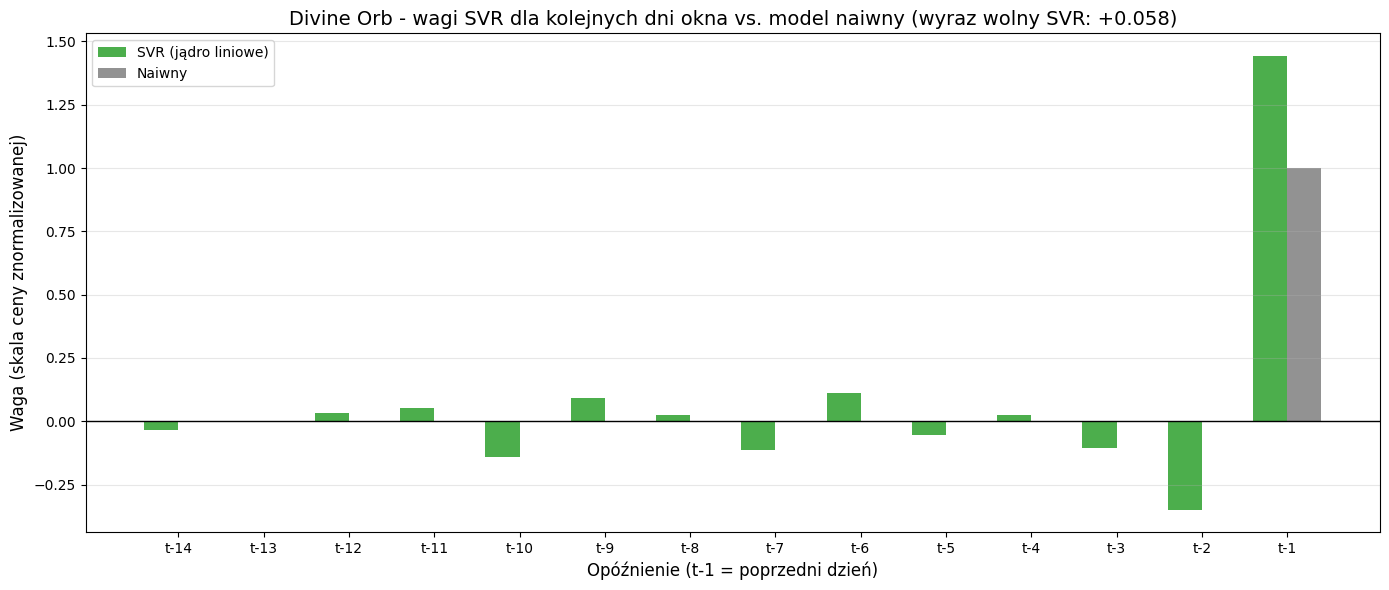

In [25]:
import os

EXPORT_DIR = 'plots'
EXPORT_FORMATS = ['png', 'pdf']
EXPORT_DPI = 300
os.makedirs(EXPORT_DIR, exist_ok=True)

svr_best = svr_grid.best_estimator_
if svr_best.kernel != 'linear':
    raise ValueError(f"coef_ istnieje tylko dla jądra 'linear', a najlepszy SVR ma '{svr_best.kernel}'")

# współczynniki na cechach po standaryzacji
w_std = svr_best.coef_.ravel()
b_std = svr_best.intercept_[0]

# przeliczenie na skalę oryginalnych cen znormalizowanych (cena / cena z 1. dnia):
# pred = w_std . (x - mean)/scale + b_std = (w_std/scale) . x + (b_std - sum(w_std*mean/scale))
w_orig = w_std / scaler_standard.scale_
b_orig = b_std - np.sum(w_std * scaler_standard.mean_ / scaler_standard.scale_)

# kontrola poprawności przeliczenia
check = np.allclose(svr_best.predict(X_train_standard[:50]), X_train[:50] @ w_orig + b_orig)
print(f'Przeliczenie współczynników poprawne: {check}')

lags = [f't-{WINDOW - i}' for i in range(WINDOW)]      # t-14 ... t-1 (t-1 = wczoraj)
df_coef = pd.DataFrame({
    'Opóźnienie': lags,
    'współczynnik (standaryzowany)': w_std,
    'waga (skala ceny znormalizowanej)': w_orig,
}).set_index('Opóźnienie')
print(df_coef.round(4).to_string())

print(f'\nWyraz wolny (skala ceny znormalizowanej): {b_orig:.4f}')
print(f'Waga dla t-1 (wczoraj):                   {w_orig[-1]:.4f}')
print(f'Suma wag t-14 ... t-2:                    {w_orig[:-1].sum():.4f}')
print(f'Suma wszystkich wag:                      {w_orig.sum():.4f}')
print('Model naiwny dla porównania: waga t-1 = 1, pozostałe wagi = 0, wyraz wolny = 0')

# wykres: wagi SVR vs model naiwny
naive_w = np.zeros(WINDOW)
naive_w[-1] = 1.0
x = np.arange(WINDOW)
w = 0.4
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - w / 2, w_orig, w, color='tab:green', alpha=0.85, label='SVR (jądro liniowe)')
ax.bar(x + w / 2, naive_w, w, color='tab:gray', alpha=0.85, label='Naiwny')
ax.axhline(0, color='black', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(lags)
ax.set_xlabel('Opóźnienie (t-1 = poprzedni dzień)', fontsize=12)
ax.set_ylabel('Waga (skala ceny znormalizowanej)', fontsize=12)
ax.set_title(f'{ITEM} - wagi SVR dla kolejnych dni okna vs. model naiwny '
             f'(wyraz wolny SVR: {b_orig:+.3f})', fontsize=14)
ax.grid(alpha=0.3, axis='y')
ax.legend(loc='best')
plt.tight_layout()
for ext in EXPORT_FORMATS:
    fig.savefig(os.path.join(EXPORT_DIR, f'{ITEM.replace(" ", "_")}_svr_wagi.{ext}'),
                dpi=EXPORT_DPI, bbox_inches='tight', facecolor='white')
plt.show()